# TASK 1: DATA COLLECTION AND UNDERSTANDING

## 1.1 Dataset Loading and Inspection

## 1.2 Dataset Structure (Rows and Columns)

## 1.3 Understanding Column Names and Data Types

## 1.4 Data Dictionary

## 1.5 Descriptive Statistics

## 1.6 Initial Missing Value Assessment

## 1.7 Summary and Observations

In [57]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [58]:
from pathlib import Path

# Main project folder in Google Drive
PROJECT_DIR = Path(
    "/content/drive/MyDrive/Customer Personality Analysis"
)

# Project subfolders
folders = [
    "01_Original_Dataset",
    "02_Cleaned_Dataset",
    "03_Colab_Notebooks",
    "04_Charts_and_Visuals",
    "05_Worksheet_and_Reports",
    "06_Presentation",
    "07_Exports_and_Backups"
]

# Create folders without deleting existing files
PROJECT_DIR.mkdir(parents=True, exist_ok=True)

for folder in folders:
    (PROJECT_DIR / folder).mkdir(exist_ok=True)

print("Project storage setup completed!")
print("\nProject location:", PROJECT_DIR)

print("\nFolder structure:")
for folder in folders:
    print("✓", folder)

Project storage setup completed!

Project location: /content/drive/MyDrive/Customer Personality Analysis

Folder structure:
✓ 01_Original_Dataset
✓ 02_Cleaned_Dataset
✓ 03_Colab_Notebooks
✓ 04_Charts_and_Visuals
✓ 05_Worksheet_and_Reports
✓ 06_Presentation
✓ 07_Exports_and_Backups


In [59]:
import os

for root, dirs, files in os.walk(PROJECT_DIR):
    level = root.replace(str(PROJECT_DIR), "").count(os.sep)
    indent = " " * 4 * level
    print(f"{indent}{os.path.basename(root)}/")


Customer Personality Analysis/
    01_Original_Dataset/
    02_Cleaned_Dataset/
    03_Colab_Notebooks/
    04_Charts_and_Visuals/
    05_Worksheet_and_Reports/
    06_Presentation/
    07_Exports_and_Backups/


In [60]:
from pathlib import Path

original_folder = PROJECT_DIR / "01_Original_Dataset"

print("Files in Original Dataset folder:")

for file in original_folder.iterdir():
    if file.is_file():
        print(file.name, "|", round(file.stat().st_size / 1024, 2), "KB")

Files in Original Dataset folder:
972212_b064907031e84695a9fa1f84d0cd73df.xlsx | 257.54 KB


In [61]:
import pandas as pd
from pathlib import Path

# Register the original dataset path
ORIGINAL_FILE = (
    PROJECT_DIR
    / "01_Original_Dataset"
    / "972212_b064907031e84695a9fa1f84d0cd73df.xlsx"
)

# Check that the file exists
print("File exists:", ORIGINAL_FILE.exists())
print("File size:", round(ORIGINAL_FILE.stat().st_size / 1024, 2), "KB")

# Inspect Excel workbook sheets
excel_file = pd.ExcelFile(ORIGINAL_FILE)

print("\nWorksheets available:")
for sheet in excel_file.sheet_names:
    print("-", sheet)

File exists: True
File size: 257.54 KB

Worksheets available:
- June22_DA


In [62]:
# Read the first worksheet for inspection
original_df = pd.read_excel(
    ORIGINAL_FILE,
    sheet_name=excel_file.sheet_names[0]
)

print("DATASET OVERVIEW")
print("-" * 40)

print("Number of rows:", original_df.shape[0])
print("Number of columns:", original_df.shape[1])

print("\nColumn names:")
print(original_df.columns.tolist())

print("\nFirst 5 records:")
display(original_df.head())

print("\nDataset information:")
original_df.info()

DATASET OVERVIEW
----------------------------------------
Number of rows: 2240
Number of columns: 29

Column names:
['ID', 'Year_Birth', 'Education', 'Marital_Status', 'Income', 'Kidhome', 'Teenhome', 'Dt_Customer', 'Recency', 'MntWines', 'MntFruits', 'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts', 'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth', 'AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5', 'AcceptedCmp1', 'AcceptedCmp2', 'Complain', 'Z_CostContact', 'Z_Revenue', 'Response']

First 5 records:


,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,58138.0,0,0,2012-04-09 00:00:00,58,635,...,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,46344.0,1,1,2014-08-03 00:00:00,38,11,...,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,4,0,0,0,0,0,0,3,11,0
3,6182,1984,Graduation,Together,26646.0,1,0,2014-10-02 00:00:00,26,11,...,6,0,0,0,0,0,0,3,11,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,5,0,0,0,0,0,0,3,11,0



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2240 entries, 0 to 2239
Data columns (total 29 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ID                   2240 non-null   int64  
 1   Year_Birth           2240 non-null   int64  
 2   Education            2240 non-null   object 
 3   Marital_Status       2240 non-null   object 
 4   Income               2216 non-null   float64
 5   Kidhome              2240 non-null   int64  
 6   Teenhome             2240 non-null   int64  
 7   Dt_Customer          2240 non-null   object 
 8   Recency              2240 non-null   int64  
 9   MntWines             2240 non-null   int64  
 10  MntFruits            2240 non-null   int64  
 11  MntMeatProducts      2240 non-null   int64  
 12  MntFishProducts      2240 non-null   int64  
 13  MntSweetProducts     2240 non-null   int64  
 14  MntGoldProds         2240 non-null   int64  
 15  NumDealsPurchase

In [63]:
# TASK 1: DATA DICTIONARY

data_dictionary = {
    "ID": "Unique customer identification number",
    "Year_Birth": "Customer's year of birth",
    "Education": "Customer's education level",
    "Marital_Status": "Customer's marital status",
    "Income": "Customer's yearly household income",
    "Kidhome": "Number of small children in the household",
    "Teenhome": "Number of teenagers in the household",
    "Dt_Customer": "Date when the customer enrolled with the company",
    "Recency": "Number of days since the customer's last purchase",
    "MntWines": "Amount spent on wine products",
    "MntFruits": "Amount spent on fruit products",
    "MntMeatProducts": "Amount spent on meat products",
    "MntFishProducts": "Amount spent on fish products",
    "MntSweetProducts": "Amount spent on sweet products",
    "MntGoldProds": "Amount spent on gold products",
    "NumDealsPurchases": "Number of purchases made using discounts",
    "NumWebPurchases": "Number of purchases made through the website",
    "NumCatalogPurchases": "Number of purchases made through the catalogue",
    "NumStorePurchases": "Number of purchases made in physical stores",
    "NumWebVisitsMonth": "Number of website visits in the last month",
    "AcceptedCmp3": "Whether customer accepted campaign 3",
    "AcceptedCmp4": "Whether customer accepted campaign 4",
    "AcceptedCmp5": "Whether customer accepted campaign 5",
    "AcceptedCmp1": "Whether customer accepted campaign 1",
    "AcceptedCmp2": "Whether customer accepted campaign 2",
    "Complain": "Whether customer made a complaint",
    "Z_CostContact": "Constant contact-cost variable in the dataset",
    "Z_Revenue": "Constant revenue variable in the dataset",
    "Response": "Whether customer accepted the latest campaign"
}

column_categories = {
    "Customer Identification": ["ID"],
    "Demographics": ["Year_Birth", "Education", "Marital_Status"],
    "Household Information": ["Income", "Kidhome", "Teenhome"],
    "Customer Relationship": ["Dt_Customer", "Recency"],
    "Product Spending": [
        "MntWines", "MntFruits", "MntMeatProducts",
        "MntFishProducts", "MntSweetProducts", "MntGoldProds"
    ],
    "Purchase Behaviour": [
        "NumDealsPurchases", "NumWebPurchases",
        "NumCatalogPurchases", "NumStorePurchases",
        "NumWebVisitsMonth"
    ],
    "Marketing Campaigns": [
        "AcceptedCmp1", "AcceptedCmp2", "AcceptedCmp3",
        "AcceptedCmp4", "AcceptedCmp5", "Response"
    ],
    "Customer Feedback": ["Complain"],
    "Constant Variables": ["Z_CostContact", "Z_Revenue"]
}

dictionary_df = pd.DataFrame({
    "Column": list(data_dictionary.keys()),
    "Description": list(data_dictionary.values())
})

dictionary_df["Category"] = dictionary_df["Column"].map(
    {
        col: category
        for category, columns in column_categories.items()
        for col in columns
    }
)

display(dictionary_df)

,Column,Description,Category
0,ID,Unique customer identification number,Customer Identification
1,Year_Birth,Customer's year of birth,Demographics
2,Education,Customer's education level,Demographics
3,Marital_Status,Customer's marital status,Demographics
4,Income,Customer's yearly household income,Household Information
5,Kidhome,Number of small children in the household,Household Information
6,Teenhome,Number of teenagers in the household,Household Information
7,Dt_Customer,Date when the customer enrolled with the company,Customer Relationship
8,Recency,Number of days since the customer's last purchase,Customer Relationship
9,MntWines,Amount spent on wine products,Product Spending


In [64]:
# TASK 1: INITIAL DATA QUALITY REPORT

print("DATA QUALITY BASELINE")
print("=" * 50)

print("\nDataset dimensions:")
print("Rows:", original_df.shape[0])
print("Columns:", original_df.shape[1])

print("\nMissing values:")
missing_report = pd.DataFrame({
    "Missing_Count": original_df.isnull().sum(),
    "Missing_Percentage": (
        original_df.isnull().mean() * 100
    ).round(2)
})

display(missing_report[missing_report["Missing_Count"] > 0])

print("\nExact duplicate rows:")
print(original_df.duplicated().sum())

print("\nDuplicate customer IDs:")
print(original_df["ID"].duplicated().sum())

print("\nData types:")
display(original_df.dtypes.astype(str).to_frame("Data_Type"))

print("\nNumerical summary:")
display(original_df.describe().T)

DATA QUALITY BASELINE

Dataset dimensions:
Rows: 2240
Columns: 29

Missing values:


,Missing_Count,Missing_Percentage
Income,24,1.07



Exact duplicate rows:
0

Duplicate customer IDs:
0

Data types:


,Data_Type
ID,int64
Year_Birth,int64
Education,object
Marital_Status,object
Income,float64
Kidhome,int64
Teenhome,int64
Dt_Customer,object
Recency,int64
MntWines,int64



Numerical summary:


,count,mean,std,min,25%,50%,75%,max
ID,2240.0,5592.159821,3246.662198,0.0,2828.25,5458.5,8427.75,11191.0
Year_Birth,2240.0,1968.805804,11.984069,1893.0,1959.00,1970.0,1977.00,1996.0
Income,2216.0,52247.251354,25173.076661,1730.0,35303.00,51381.5,68522.00,666666.0
Kidhome,2240.0,0.444196,0.538398,0.0,0.00,0.0,1.00,2.0
Teenhome,2240.0,0.506250,0.544538,0.0,0.00,0.0,1.00,2.0
Recency,2240.0,49.109375,28.962453,0.0,24.00,49.0,74.00,99.0
MntWines,2240.0,303.935714,336.597393,0.0,23.75,173.5,504.25,1493.0
MntFruits,2240.0,26.302232,39.773434,0.0,1.00,8.0,33.00,199.0
MntMeatProducts,2240.0,166.950000,225.715373,0.0,16.00,67.0,232.00,1725.0
MntFishProducts,2240.0,37.525446,54.628979,0.0,3.00,12.0,50.00,259.0


In [65]:
# Save Task 1 documentation and baseline reports

REPORT_FOLDER = PROJECT_DIR / "05_Worksheet_and_Reports"
REPORT_FOLDER.mkdir(exist_ok=True)

dictionary_df.to_csv(
    REPORT_FOLDER / "Task1_Data_Dictionary.csv",
    index=False
)

missing_report.to_csv(
    REPORT_FOLDER / "Task1_Missing_Value_Baseline.csv"
)

original_df.describe(include="all").T.to_csv(
    REPORT_FOLDER / "Task1_Descriptive_Summary.csv"
)

print("Task 1 reports saved successfully!")

Task 1 reports saved successfully!


In [66]:
# Verify Task 1 reports are stored in Drive

print("TASK 1 REPORTS")
for file in sorted(REPORT_FOLDER.iterdir()):
    if file.is_file():
        print("✓", file.name)

print("\nNOTEBOOK AND REPORT STORAGE READY")

TASK 1 REPORTS
✓ Task1_Data_Dictionary.csv
✓ Task1_Descriptive_Summary.csv
✓ Task1_Missing_Value_Baseline.csv
✓ Task2_Cleaning_Report.xlsx
✓ Task3_Correlation_Matrix.csv
✓ Task3_Descriptive_Statistics.csv
✓ Task3_EDA_Key_Findings.csv
✓ Task3_Product_Category_Summary.csv
✓ Task3_Purchase_Channel_Summary.csv
✓ Task4_Customer_Spending_Profiles.csv
✓ Task4_Household_Spending_Analysis.csv
✓ Task4_Income_Group_Spending.csv
✓ Task4_Product_Spending_Analysis.csv
✓ Task4_Spending_Analysis_Key_Findings.csv
✓ Task5_Acceptance_by_Education.csv
✓ Task5_Acceptance_by_Marital_Status.csv
✓ Task5_Campaign_Acceptance_Correlation.csv
✓ Task5_Campaign_Acceptance_Rates.csv
✓ Task5_Customer_Acceptance_Comparison.csv
✓ Task5_Discount_Purchase_Behaviour.csv
✓ Task6_Channel_Preferences_by_Income.csv
✓ Task6_Channel_Summary.csv
✓ Task6_Web_Visits_vs_Purchases.csv
✓ Task7_Cluster_Profiles.csv
✓ Task7_Cluster_Summary.csv
✓ Task7_Silhouette_Scores.csv
✓ Task8_Business_Recommendations.csv
✓ internship_overview_task

In [67]:
from pathlib import Path

for folder_name in [
    "01_Original_Dataset",
    "02_Cleaned_Dataset",
    "03_Colab_Notebooks",
    "05_Worksheet_and_Reports"
]:
    folder = PROJECT_DIR / folder_name

    print(f"\n📁 {folder_name}")
    for file in sorted(folder.iterdir()):
        if file.is_file():
            print("  ✓", file.name)


📁 01_Original_Dataset
  ✓ 972212_b064907031e84695a9fa1f84d0cd73df.xlsx

📁 02_Cleaned_Dataset
  ✓ clean_data.csv

📁 03_Colab_Notebooks
  ✓ Customer_Personality_Analysis_Setup.ipynb

📁 05_Worksheet_and_Reports
  ✓ Task1_Data_Dictionary.csv
  ✓ Task1_Descriptive_Summary.csv
  ✓ Task1_Missing_Value_Baseline.csv
  ✓ Task2_Cleaning_Report.xlsx
  ✓ Task3_Correlation_Matrix.csv
  ✓ Task3_Descriptive_Statistics.csv
  ✓ Task3_EDA_Key_Findings.csv
  ✓ Task3_Product_Category_Summary.csv
  ✓ Task3_Purchase_Channel_Summary.csv
  ✓ Task4_Customer_Spending_Profiles.csv
  ✓ Task4_Household_Spending_Analysis.csv
  ✓ Task4_Income_Group_Spending.csv
  ✓ Task4_Product_Spending_Analysis.csv
  ✓ Task4_Spending_Analysis_Key_Findings.csv
  ✓ Task5_Acceptance_by_Education.csv
  ✓ Task5_Acceptance_by_Marital_Status.csv
  ✓ Task5_Campaign_Acceptance_Correlation.csv
  ✓ Task5_Campaign_Acceptance_Rates.csv
  ✓ Task5_Customer_Acceptance_Comparison.csv
  ✓ Task5_Discount_Purchase_Behaviour.csv
  ✓ Task6_Channel_Pref

In [68]:
INSTRUCTIONS_FILE = PROJECT_DIR / "05_Worksheet_and_Reports" / "internship_overview_tasks_instructions.md"

instructions_text = INSTRUCTIONS_FILE.read_text(encoding="utf-8")

print(instructions_text)

# CHEARS Data Analyst Internship: Customer Data Analysis Project

Compiled from the CHEARS portal screenshots and the "Tasks and detailed guide" file.

---

## 1. Overview

A one-month internship giving hands-on experience in data analysis using real-world customer data. Interns work with a customer marketing dataset to clean, explore, analyze, and visualize data to find meaningful patterns and business insights. Interns may choose any analytical tool, programming language, or IDE. The internship emphasizes practical learning, analytical thinking, data interpretation, and communicating findings effectively.

| Item | Detail |
|------|--------|
| Duration | 1 Month |
| Project type | Individual Data Analysis Project |
| Dataset | Customer Personality and Marketing Analysis |
| Presentation | Maximum 15 slides |
| Final video | Mandatory |
| Maximum video duration | 5 minutes |
| Maximum presentation length | 15 slides |

---

## 2. Project Description

**Objective:** Explore the dataset

# TASK 2: DATA CLEANING AND PREPROCESSING



## 2.1 Data Quality Assessment

In [69]:
# TASK 2 — STEP 1: DATA QUALITY BASELINE

import pandas as pd
import numpy as np

# Work on a separate copy; never modify original_df
clean_df = original_df.copy(deep=True)

print("Dataset shape:", clean_df.shape)
print("\nData types:")
display(clean_df.dtypes.to_frame("Data_Type"))

print("\nMissing values:")
missing_report = pd.DataFrame({
    "Missing_Count": clean_df.isna().sum(),
    "Missing_Percentage": (
        clean_df.isna().mean() * 100
    ).round(2)
})
display(missing_report)

print("\nExact duplicate rows:", clean_df.duplicated().sum())

print("\nNumerical summary:")
display(clean_df.describe().T)

print("\nCategorical summary:")
display(clean_df.describe(include="object").T)

Dataset shape: (2240, 29)

Data types:


,Data_Type
ID,int64
Year_Birth,int64
Education,object
Marital_Status,object
Income,float64
Kidhome,int64
Teenhome,int64
Dt_Customer,object
Recency,int64
MntWines,int64



Missing values:


,Missing_Count,Missing_Percentage
ID,0,0.00
Year_Birth,0,0.00
Education,0,0.00
Marital_Status,0,0.00
Income,24,1.07
Kidhome,0,0.00
Teenhome,0,0.00
Dt_Customer,0,0.00
Recency,0,0.00
MntWines,0,0.00



Exact duplicate rows: 0

Numerical summary:


,count,mean,std,min,25%,50%,75%,max
ID,2240.0,5592.159821,3246.662198,0.0,2828.25,5458.5,8427.75,11191.0
Year_Birth,2240.0,1968.805804,11.984069,1893.0,1959.00,1970.0,1977.00,1996.0
Income,2216.0,52247.251354,25173.076661,1730.0,35303.00,51381.5,68522.00,666666.0
Kidhome,2240.0,0.444196,0.538398,0.0,0.00,0.0,1.00,2.0
Teenhome,2240.0,0.506250,0.544538,0.0,0.00,0.0,1.00,2.0
Recency,2240.0,49.109375,28.962453,0.0,24.00,49.0,74.00,99.0
MntWines,2240.0,303.935714,336.597393,0.0,23.75,173.5,504.25,1493.0
MntFruits,2240.0,26.302232,39.773434,0.0,1.00,8.0,33.00,199.0
MntMeatProducts,2240.0,166.950000,225.715373,0.0,16.00,67.0,232.00,1725.0
MntFishProducts,2240.0,37.525446,54.628979,0.0,3.00,12.0,50.00,259.0



Categorical summary:


,count,unique,top,freq
Education,2240,5,Graduation,1127
Marital_Status,2240,8,Married,864
Dt_Customer,2240,663,31-08-2012,12


## 2.2 Inspect Unusual Values

In [70]:
# TASK 2 — STEP 2: INSPECT UNUSUAL VALUES

# 1. Check birth year values
print("Birth year frequency:")
display(clean_df["Year_Birth"].value_counts().sort_index())

# 2. Check marital status categories
print("\nMarital status categories:")
display(clean_df["Marital_Status"].value_counts())

# 3. Check education categories
print("\nEducation categories:")
display(clean_df["Education"].value_counts())

# 4. Inspect unusually high income records
print("\nHighest 10 income records:")
display(
    clean_df[["ID", "Income"]]
    .sort_values("Income", ascending=False)
    .head(10)
)

# 5. Check for negative spending values
spending_cols = [
    "MntWines", "MntFruits", "MntMeatProducts",
    "MntFishProducts", "MntSweetProducts", "MntGoldProds"
]

print("\nNegative spending values:")
display((clean_df[spending_cols] < 0).sum())

# 6. Inspect date values
print("\nSample customer enrollment dates:")
display(clean_df["Dt_Customer"].head(15))

Birth year frequency:


,count
Year_Birth,
1893,1
1899,1
1900,1
1940,1
1941,1
1943,7
1944,7
1945,8
1946,16



Marital status categories:


,count
Marital_Status,
Married,864
Together,580
Single,480
Divorced,232
Widow,77
Alone,3
Absurd,2
YOLO,2



Education categories:


,count
Education,
Graduation,1127
PhD,486
Master,370
2n Cycle,203
Basic,54


... (2 outputs left out)


Negative spending values:


,0
MntWines,0
MntFruits,0
MntMeatProducts,0
MntFishProducts,0
MntSweetProducts,0
MntGoldProds,0



Sample customer enrollment dates:


,Dt_Customer
0,2012-04-09 00:00:00
1,2014-08-03 00:00:00
2,21-08-2013
3,2014-10-02 00:00:00
4,19-01-2014
5,2013-09-09 00:00:00
6,13-11-2012
7,2013-08-05 00:00:00
8,2013-06-06 00:00:00
9,13-03-2014


## 2.3 Initial *Cleaning*

In [71]:
# TASK 2 — STEP 3: INITIAL CLEANING

# Keep a record of cleaning operations
cleaning_log = []

# 1. Handle invalid birth years
invalid_birth_years = [1893, 1899, 1900]

birth_year_mask = clean_df["Year_Birth"].isin(invalid_birth_years)
birth_year_count = birth_year_mask.sum()

clean_df.loc[birth_year_mask, "Year_Birth"] = np.nan

cleaning_log.append({
    "Operation": "Invalid birth years",
    "Details": f"Set {birth_year_count} invalid birth years to missing",
    "Records_Affected": birth_year_count
})

# 2. Standardize unusual marital status labels
marital_mapping = {
    "Absurd": "Single",
    "YOLO": "Single",
    "Alone": "Single"
}

marital_count = clean_df["Marital_Status"].isin(
    marital_mapping.keys()
).sum()

clean_df["Marital_Status"] = clean_df["Marital_Status"].replace(
    marital_mapping
)

cleaning_log.append({
    "Operation": "Marital status standardization",
    "Details": "Mapped Absurd, YOLO and Alone to Single",
    "Records_Affected": marital_count
})

# 3. Check remaining missing values
print("Missing values after initial cleaning:")
display(clean_df.isna().sum().to_frame("Missing_Count"))

# 4. Display updated categories
print("\nUpdated marital status:")
display(clean_df["Marital_Status"].value_counts())

# 5. Display cleaning log
print("\nCleaning log:")
display(pd.DataFrame(cleaning_log))

Missing values after initial cleaning:


,Missing_Count
ID,0
Year_Birth,3
Education,0
Marital_Status,0
Income,24
Kidhome,0
Teenhome,0
Dt_Customer,0
Recency,0
MntWines,0



Updated marital status:


,count
Marital_Status,
Married,864
Together,580
Single,487
Divorced,232
Widow,77



Cleaning log:


,Operation,Details,Records_Affected
0,Invalid birth years,Set 3 invalid birth years to missing,3
1,Marital status standardization,"Mapped Absurd, YOLO and Alone to Single",7


## 2.4 Impute Missing Income

In [72]:
## TASK 2 — STEP 4: IMPUTE MISSING INCOME

# Count missing income values before imputation
missing_income_before = clean_df["Income"].isna().sum()

# Calculate median income for each Education group
education_medians = clean_df.groupby("Education")["Income"].median()

print("Median income by Education group:")
display(education_medians.to_frame("Median_Income"))

# Fill missing Income values using the corresponding group median
clean_df["Income"] = clean_df["Income"].fillna(
    clean_df.groupby("Education")["Income"].transform("median")
)

# Count missing income values after imputation
missing_income_after = clean_df["Income"].isna().sum()

# Record the operation
cleaning_log.append({
    "Operation": "Missing income imputation",
    "Details": "Filled missing Income values using median within each Education group",
    "Records_Affected": missing_income_before - missing_income_after
})

print("\nMissing Income before:", missing_income_before)
print("Missing Income after:", missing_income_after)

print("\nUpdated Income summary:")
display(clean_df["Income"].describe())

print("\nUpdated cleaning log:")
display(pd.DataFrame(cleaning_log))


Median income by Education group:


,Median_Income
Education,
2n Cycle,46805.0
Basic,20744.0
Graduation,52028.5
Master,50943.0
PhD,55212.0



Missing Income before: 24
Missing Income after: 0

Updated Income summary:


,Income
count,2240.000000
mean,52242.594866
std,25039.061738
min,1730.000000
25%,35538.750000
50%,51498.500000
75%,68289.750000
max,666666.000000



Updated cleaning log:


,Operation,Details,Records_Affected
0,Invalid birth years,Set 3 invalid birth years to missing,3
1,Marital status standardization,"Mapped Absurd, YOLO and Alone to Single",7
2,Missing income imputation,Filled missing Income values using median with...,24


## 2.5 Inspect Date Formats

In [73]:
# TASK 2 — STEP 5: INSPECT DATE FORMATS

date_col = clean_df["Dt_Customer"]

print("Data type of Dt_Customer:", date_col.dtype)

# Count the underlying Python value types
print("\nValue types:")
display(
    date_col.apply(lambda x: type(x).__name__)
    .value_counts()
    .to_frame("Count")
)

# Show examples of text dates
text_dates = date_col[
    date_col.apply(lambda x: isinstance(x, str))
]

print("\nText date examples:")
display(text_dates.head(15))

# Show examples of values already stored as dates
date_values = date_col[
    date_col.apply(
        lambda x: isinstance(x, (pd.Timestamp, np.datetime64))
    )
]

print("\nExisting date examples:")
display(date_values.head(15))

print("\nTotal records:", len(date_col))
print("Text date records:", len(text_dates))
print("Existing date records:", len(date_values))

Data type of Dt_Customer: object

Value types:


,Count
Dt_Customer,
str,1324
datetime,916



Text date examples:


,Dt_Customer
2,21-08-2013
4,19-01-2014
6,13-11-2012
9,13-03-2014
10,15-11-2013
11,13-11-2012
12,15-11-2013
13,15-11-2013
15,24-11-2012
16,24-12-2012



Existing date examples:


,Dt_Customer



Total records: 2240
Text date records: 1324
Existing date records: 0


## 2.6 Standardize Enrollment Dates

In [74]:
# TASK 2 — STEP 6: STANDARDIZE ENROLLMENT DATES

# Create a separate standardized date column
clean_df["Dt_Customer_Std"] = pd.NaT

# Identify text date records
text_mask = clean_df["Dt_Customer"].apply(
    lambda x: isinstance(x, str)
)

# Parse text dates using the confirmed day-month-year format
clean_df.loc[text_mask, "Dt_Customer_Std"] = pd.to_datetime(
    clean_df.loc[text_mask, "Dt_Customer"],
    format="%d-%m-%Y",
    errors="coerce"
)

# Identify records already stored as datetime objects
datetime_mask = clean_df["Dt_Customer"].apply(
    lambda x: isinstance(x, (pd.Timestamp, __import__("datetime").datetime))
)

# Create a status column to document how dates were handled
clean_df["Dt_Customer_Status"] = "Unrecognized format"
clean_df.loc[text_mask, "Dt_Customer_Status"] = "Parsed from DD-MM-YYYY text"
clean_df.loc[datetime_mask, "Dt_Customer_Status"] = (
    "Unresolved original datetime format"
)

# Record the operation
cleaning_log.append({
    "Operation": "Enrollment date standardization",
    "Details": (
        "Parsed identifiable DD-MM-YYYY text dates; "
        "left original datetime values unresolved"
    ),
    "Records_Affected": int(text_mask.sum())
})

print("Date status counts:")
display(clean_df["Dt_Customer_Status"].value_counts().to_frame("Count"))

print("\nStandardized date examples:")
display(
    clean_df[
        ["Dt_Customer", "Dt_Customer_Std", "Dt_Customer_Status"]
    ].head(20)
)

print("\nStandardized date range:")
print("Earliest:", clean_df["Dt_Customer_Std"].min())
print("Latest:", clean_df["Dt_Customer_Std"].max())

print("\nMissing standardized dates:", clean_df["Dt_Customer_Std"].isna().sum())

Date status counts:


,Count
Dt_Customer_Status,
Parsed from DD-MM-YYYY text,1324
Unresolved original datetime format,916



Standardized date examples:


,Dt_Customer,Dt_Customer_Std,Dt_Customer_Status
0,2012-04-09 00:00:00,NaT,Unresolved original datetime format
1,2014-08-03 00:00:00,NaT,Unresolved original datetime format
2,21-08-2013,2013-08-21,Parsed from DD-MM-YYYY text
3,2014-10-02 00:00:00,NaT,Unresolved original datetime format
4,19-01-2014,2014-01-19,Parsed from DD-MM-YYYY text
5,2013-09-09 00:00:00,NaT,Unresolved original datetime format
6,13-11-2012,2012-11-13,Parsed from DD-MM-YYYY text
7,2013-08-05 00:00:00,NaT,Unresolved original datetime format
8,2013-06-06 00:00:00,NaT,Unresolved original datetime format
9,13-03-2014,2014-03-13,Parsed from DD-MM-YYYY text



Standardized date range:
Earliest: 2012-07-30 00:00:00
Latest: 2014-06-29 00:00:00

Missing standardized dates: 916


## 2.7 Detect Income Outliers

In [75]:
# TASK 2 — STEP 7: DETECT INCOME OUTLIERS

# Calculate quartiles and IQR
Q1 = clean_df["Income"].quantile(0.25)
Q3 = clean_df["Income"].quantile(0.75)
IQR = Q3 - Q1

# Calculate IQR boundaries
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Flag outliers
clean_df["Income_Outlier_Flag"] = np.where(
    (clean_df["Income"] < lower_bound) |
    (clean_df["Income"] > upper_bound),
    "Yes",
    "No"
)

# Count outliers
outlier_count = (clean_df["Income_Outlier_Flag"] == "Yes").sum()

# Record operation
cleaning_log.append({
    "Operation": "Income outlier detection",
    "Details": f"IQR method; lower={lower_bound:.2f}, upper={upper_bound:.2f}; values retained",
    "Records_Affected": int(outlier_count)
})

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower boundary:", lower_bound)
print("Upper boundary:", upper_bound)

print("\nNumber of income outliers:", outlier_count)

print("\nOutlier records:")
display(
    clean_df.loc[
        clean_df["Income_Outlier_Flag"] == "Yes",
        ["ID", "Education", "Income", "Income_Outlier_Flag"]
    ].sort_values("Income", ascending=False)
)

print("\nIncome values remain unchanged:")
print("Maximum income:", clean_df["Income"].max())

Q1: 35538.75
Q3: 68289.75
IQR: 32751.0
Lower boundary: -13587.75
Upper boundary: 117416.25

Number of income outliers: 8

Outlier records:


,ID,Education,Income,Income_Outlier_Flag
2233,9432,Graduation,666666.0,Yes
617,1503,PhD,162397.0,Yes
687,1501,PhD,160803.0,Yes
1300,5336,Master,157733.0,Yes
164,8475,PhD,157243.0,Yes
1653,4931,Graduation,157146.0,Yes
2132,11181,PhD,156924.0,Yes
655,5555,Graduation,153924.0,Yes



Income values remain unchanged:
Maximum income: 666666.0


## 2.8 Create Derived Customer Features

In [76]:
# TASK 2 — STEP 8: CREATE DERIVED CUSTOMER FEATURES

# Reference year for this historical dataset
REFERENCE_YEAR = 2024

# 1. Age
clean_df["Age"] = REFERENCE_YEAR - clean_df["Year_Birth"]

# 2. Total spending across all product categories
spending_cols = [
    "MntWines",
    "MntFruits",
    "MntMeatProducts",
    "MntFishProducts",
    "MntSweetProducts",
    "MntGoldProds"
]

clean_df["TotalSpending"] = clean_df[spending_cols].sum(axis=1)

# 3. Total children at home
clean_df["TotalChildren"] = (
    clean_df["Kidhome"] + clean_df["Teenhome"]
)

# 4. Total purchases across shopping channels
# NumDealsPurchases is not added because it can overlap with channel purchases.
purchase_cols = [
    "NumWebPurchases",
    "NumCatalogPurchases",
    "NumStorePurchases"
]

clean_df["TotalPurchases"] = clean_df[purchase_cols].sum(axis=1)

# 5. Total accepted campaigns
campaign_cols = [
    "AcceptedCmp1",
    "AcceptedCmp2",
    "AcceptedCmp3",
    "AcceptedCmp4",
    "AcceptedCmp5",
    "Response"
]

clean_df["TotalCampaignsAccepted"] = clean_df[campaign_cols].sum(axis=1)

# Record operation
cleaning_log.append({
    "Operation": "Derived customer features",
    "Details": "Created Age, TotalSpending, TotalChildren, TotalPurchases and TotalCampaignsAccepted",
    "Records_Affected": len(clean_df)
})

# Display sample
derived_cols = [
    "ID",
    "Year_Birth",
    "Age",
    "TotalSpending",
    "TotalChildren",
    "TotalPurchases",
    "TotalCampaignsAccepted"
]

print("Sample derived features:")
display(clean_df[derived_cols].head(10))

print("\nDerived feature summary:")
display(clean_df[
    [
        "Age",
        "TotalSpending",
        "TotalChildren",
        "TotalPurchases",
        "TotalCampaignsAccepted"
    ]
].describe().T)

print("\nDataset shape after feature creation:", clean_df.shape)

Sample derived features:


,ID,Year_Birth,Age,TotalSpending,TotalChildren,TotalPurchases,TotalCampaignsAccepted
0,5524,1957.0,67.0,1617,0,22,1
1,2174,1954.0,70.0,27,2,4,0
2,4141,1965.0,59.0,776,0,20,0
3,6182,1984.0,40.0,53,1,6,0
4,5324,1981.0,43.0,422,1,14,0
5,7446,1967.0,57.0,716,1,20,0
6,965,1971.0,53.0,590,1,17,0
7,6177,1985.0,39.0,169,1,8,0
8,4855,1974.0,50.0,46,1,5,1
9,5899,1950.0,74.0,49,2,1,1



Derived feature summary:


,count,mean,std,min,25%,50%,75%,max
Age,2237.0,55.098346,11.701917,28.0,47.00,54.0,65.0,84.0
TotalSpending,2240.0,605.798214,602.249288,5.0,68.75,396.0,1045.5,2525.0
TotalChildren,2240.0,0.950446,0.751803,0.0,0.00,1.0,1.0,3.0
TotalPurchases,2240.0,12.537054,7.205741,0.0,6.00,12.0,18.0,32.0
TotalCampaignsAccepted,2240.0,0.446875,0.890543,0.0,0.00,0.0,1.0,5.0



Dataset shape after feature creation: (2240, 37)


## 2.9 Validate Checks

In [77]:
# TASK 2 — STEP 9: VALIDATION CHECKS

# 1. Verify TotalSpending
expected_spending = clean_df[spending_cols].sum(axis=1)
spending_check = clean_df["TotalSpending"].equals(expected_spending)

# 2. Verify TotalChildren
expected_children = clean_df["Kidhome"] + clean_df["Teenhome"]
children_check = clean_df["TotalChildren"].equals(expected_children)

# 3. Verify TotalPurchases
expected_purchases = clean_df[purchase_cols].sum(axis=1)
purchases_check = clean_df["TotalPurchases"].equals(expected_purchases)

# 4. Verify TotalCampaignsAccepted
expected_campaigns = clean_df[campaign_cols].sum(axis=1)
campaigns_check = clean_df["TotalCampaignsAccepted"].equals(expected_campaigns)

# Display validation results
validation_report = pd.DataFrame({
    "Check": [
        "TotalSpending calculation",
        "TotalChildren calculation",
        "TotalPurchases calculation",
        "TotalCampaignsAccepted calculation",
        "Dataset row count preserved"
    ],
    "Result": [
        "PASS" if spending_check else "FAIL",
        "PASS" if children_check else "FAIL",
        "PASS" if purchases_check else "FAIL",
        "PASS" if campaigns_check else "FAIL",
        "PASS" if len(clean_df) == len(original_df) else "FAIL"
    ]
})

display(validation_report)

# 5. Inspect constant columns
print("\nUnique values in constant columns:")
for col in ["Z_CostContact", "Z_Revenue"]:
    print(f"{col}: {clean_df[col].unique()}")

# 6. Identify all constant columns
constant_cols = [
    col for col in clean_df.columns
    if clean_df[col].nunique(dropna=False) <= 1
]

print("\nConstant columns identified:", constant_cols)

,Check,Result
0,TotalSpending calculation,PASS
1,TotalChildren calculation,PASS
2,TotalPurchases calculation,PASS
3,TotalCampaignsAccepted calculation,PASS
4,Dataset row count preserved,PASS



Unique values in constant columns:
Z_CostContact: [3]
Z_Revenue: [11]

Constant columns identified: ['Z_CostContact', 'Z_Revenue']


## 2.10 Final Cleaning and Quality Checks

In [78]:
# TASK 2 — STEP 10: FINAL CLEANING AND QUALITY CHECKS

# Remove constant columns from the working dataset
clean_df = clean_df.drop(columns=constant_cols)

# Record the operation
cleaning_log.append({
    "Operation": "Constant column removal",
    "Details": "Removed Z_CostContact and Z_Revenue because each contains only one unique value",
    "Records_Affected": 2
})

# Final missing-value report
final_missing_report = pd.DataFrame({
    "Missing_Count": clean_df.isna().sum(),
    "Missing_Percentage": (
        clean_df.isna().mean() * 100
    ).round(2)
})

# Final dataset summary
final_summary = pd.DataFrame({
    "Metric": [
        "Original rows",
        "Cleaned rows",
        "Original columns",
        "Cleaned columns",
        "Exact duplicate rows",
        "Missing Income values",
        "Missing Age values",
        "Unresolved enrollment dates",
        "Income outliers flagged"
    ],
    "Value": [
        len(original_df),
        len(clean_df),
        len(original_df.columns),
        len(clean_df.columns),
        clean_df.duplicated().sum(),
        clean_df["Income"].isna().sum(),
        clean_df["Age"].isna().sum(),
        clean_df["Dt_Customer_Std"].isna().sum(),
        (clean_df["Income_Outlier_Flag"] == "Yes").sum()
    ]
})

print("FINAL DATASET SHAPE:", clean_df.shape)

print("\nFinal summary:")
display(final_summary)

print("\nFinal missing-value report:")
display(final_missing_report)

print("\nCleaning operations:")
display(pd.DataFrame(cleaning_log))

FINAL DATASET SHAPE: (2240, 35)

Final summary:


,Metric,Value
0,Original rows,2240
1,Cleaned rows,2240
2,Original columns,29
3,Cleaned columns,35
4,Exact duplicate rows,0
5,Missing Income values,0
6,Missing Age values,3
7,Unresolved enrollment dates,916
8,Income outliers flagged,8



Final missing-value report:


,Missing_Count,Missing_Percentage
ID,0,0.00
Year_Birth,3,0.13
Education,0,0.00
Marital_Status,0,0.00
Income,0,0.00
Kidhome,0,0.00
Teenhome,0,0.00
Dt_Customer,0,0.00
Recency,0,0.00
MntWines,0,0.00



Cleaning operations:


,Operation,Details,Records_Affected
0,Invalid birth years,Set 3 invalid birth years to missing,3
1,Marital status standardization,"Mapped Absurd, YOLO and Alone to Single",7
2,Missing income imputation,Filled missing Income values using median with...,24
3,Enrollment date standardization,Parsed identifiable DD-MM-YYYY text dates; lef...,1324
4,Income outlier detection,"IQR method; lower=-13587.75, upper=117416.25; ...",8
5,Derived customer features,"Created Age, TotalSpending, TotalChildren, Tot...",2240
6,Constant column removal,Removed Z_CostContact and Z_Revenue because ea...,2


In [79]:
# SAVE TASK 2 OUTPUTS TO GOOGLE DRIVE

from pathlib import Path

CLEAN_DIR = PROJECT_DIR / "02_Cleaned_Dataset"
REPORT_DIR = PROJECT_DIR / "05_Worksheet_and_Reports"

CLEAN_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR.mkdir(parents=True, exist_ok=True)

# Save cleaned dataset as CSV
clean_csv_path = CLEAN_DIR / "clean_data.csv"
clean_df.to_csv(clean_csv_path, index=False)

# Save cleaning report as Excel with multiple sheets
report_path = REPORT_DIR / "Task2_Cleaning_Report.xlsx"

with pd.ExcelWriter(report_path, engine="openpyxl") as writer:
    final_summary.to_excel(
        writer, sheet_name="Final_Summary", index=False
    )
    final_missing_report.to_excel(
        writer, sheet_name="Missing_Values"
    )
    pd.DataFrame(cleaning_log).to_excel(
        writer, sheet_name="Cleaning_Log", index=False
    )
    validation_report.to_excel(
        writer, sheet_name="Validation", index=False
    )

print("Files saved successfully:")
print(clean_csv_path)
print(report_path)

Files saved successfully:
/content/drive/MyDrive/Customer Personality Analysis/02_Cleaned_Dataset/clean_data.csv
/content/drive/MyDrive/Customer Personality Analysis/05_Worksheet_and_Reports/Task2_Cleaning_Report.xlsx


In [80]:
print("Cleaned dataset exists:", clean_csv_path.exists())
print("Cleaning report exists:", report_path.exists())

print("\nCleaned dataset size:")
print(f"{clean_csv_path.stat().st_size / 1024:.2f} KB")

print("\nCleaning report size:")
print(f"{report_path.stat().st_size / 1024:.2f} KB")

Cleaned dataset exists: True
Cleaning report exists: True

Cleaned dataset size:
342.96 KB

Cleaning report size:
7.80 KB


# TASK 3: EXPLORATORY DATA ANALYSIS (EDA)


## 3.1 Loading and Verifying the Cleaned Dataset

In [81]:
# TASK 3 — STEP 3.1: LOAD CLEANED DATASET

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Define cleaned dataset path
CLEAN_FILE = PROJECT_DIR / "02_Cleaned_Dataset" / "clean_data.csv"

# Load cleaned dataset
eda_df = pd.read_csv(CLEAN_FILE)

# Display basic information
print("Dataset loaded successfully!")

print("\nDataset shape:")
print(eda_df.shape)

print("\nFirst 5 records:")
display(eda_df.head())

print("\nColumn names:")
print(eda_df.columns.tolist())

print("\nData types:")
display(eda_df.dtypes.to_frame("Data_Type"))

print("\nMissing values:")
display(eda_df.isna().sum().to_frame("Missing_Count"))

Dataset loaded successfully!

Dataset shape:
(2240, 35)

First 5 records:


,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,Complain,Response,Dt_Customer_Std,Dt_Customer_Status,Income_Outlier_Flag,Age,TotalSpending,TotalChildren,TotalPurchases,TotalCampaignsAccepted
0,5524,1957.0,Graduation,Single,58138.0,0,0,2012-04-09 00:00:00,58,635,...,0,1,NaN,Unresolved original datetime format,No,67.0,1617,0,22,1
1,2174,1954.0,Graduation,Single,46344.0,1,1,2014-08-03 00:00:00,38,11,...,0,0,NaN,Unresolved original datetime format,No,70.0,27,2,4,0
2,4141,1965.0,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,0,0,2013-08-21,Parsed from DD-MM-YYYY text,No,59.0,776,0,20,0
3,6182,1984.0,Graduation,Together,26646.0,1,0,2014-10-02 00:00:00,26,11,...,0,0,NaN,Unresolved original datetime format,No,40.0,53,1,6,0
4,5324,1981.0,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,0,0,2014-01-19,Parsed from DD-MM-YYYY text,No,43.0,422,1,14,0



Column names:
['ID', 'Year_Birth', 'Education', 'Marital_Status', 'Income', 'Kidhome', 'Teenhome', 'Dt_Customer', 'Recency', 'MntWines', 'MntFruits', 'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts', 'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth', 'AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5', 'AcceptedCmp1', 'AcceptedCmp2', 'Complain', 'Response', 'Dt_Customer_Std', 'Dt_Customer_Status', 'Income_Outlier_Flag', 'Age', 'TotalSpending', 'TotalChildren', 'TotalPurchases', 'TotalCampaignsAccepted']

Data types:


,Data_Type
ID,int64
Year_Birth,float64
Education,object
Marital_Status,object
Income,float64
Kidhome,int64
Teenhome,int64
Dt_Customer,object
Recency,int64
MntWines,int64



Missing values:


,Missing_Count
ID,0
Year_Birth,3
Education,0
Marital_Status,0
Income,0
Kidhome,0
Teenhome,0
Dt_Customer,0
Recency,0
MntWines,0


## 3.2 Descriptive Statistical Analysis

In [82]:
# TASK 3 — STEP 3.2: DESCRIPTIVE STATISTICS

# Select important numerical customer attributes
numeric_cols = [
    "Age",
    "Income",
    "Recency",
    "TotalSpending",
    "TotalChildren",
    "TotalPurchases",
    "TotalCampaignsAccepted",
    "NumWebVisitsMonth"
]

# Generate descriptive statistics
descriptive_stats = eda_df[numeric_cols].describe().T

# Add median and variance
descriptive_stats["Median"] = eda_df[numeric_cols].median()
descriptive_stats["Variance"] = eda_df[numeric_cols].var()

# Round values for readability
descriptive_stats = descriptive_stats.round(2)

print("Descriptive Statistics of Customer Attributes:")
display(descriptive_stats)

# Save the statistics to Google Drive
REPORT_DIR = PROJECT_DIR / "05_Worksheet_and_Reports"
REPORT_DIR.mkdir(parents=True, exist_ok=True)

descriptive_stats.to_csv(
    REPORT_DIR / "Task3_Descriptive_Statistics.csv"
)

print("\nDescriptive statistics saved successfully!")

Descriptive Statistics of Customer Attributes:


,count,mean,std,min,25%,50%,75%,max,Median,Variance
Age,2237.0,55.10,11.70,28.0,47.00,54.0,65.00,84.0,54.0,1.369300e+02
Income,2240.0,52242.59,25039.06,1730.0,35538.75,51498.5,68289.75,666666.0,51498.5,6.269546e+08
Recency,2240.0,49.11,28.96,0.0,24.00,49.0,74.00,99.0,49.0,8.388200e+02
TotalSpending,2240.0,605.80,602.25,5.0,68.75,396.0,1045.50,2525.0,396.0,3.627042e+05
TotalChildren,2240.0,0.95,0.75,0.0,0.00,1.0,1.00,3.0,1.0,5.700000e-01
TotalPurchases,2240.0,12.54,7.21,0.0,6.00,12.0,18.00,32.0,12.0,5.192000e+01
TotalCampaignsAccepted,2240.0,0.45,0.89,0.0,0.00,0.0,1.00,5.0,0.0,7.900000e-01
NumWebVisitsMonth,2240.0,5.32,2.43,0.0,3.00,6.0,7.00,20.0,6.0,5.890000e+00



Descriptive statistics saved successfully!


## 3.3 Customer Demographic Analysis

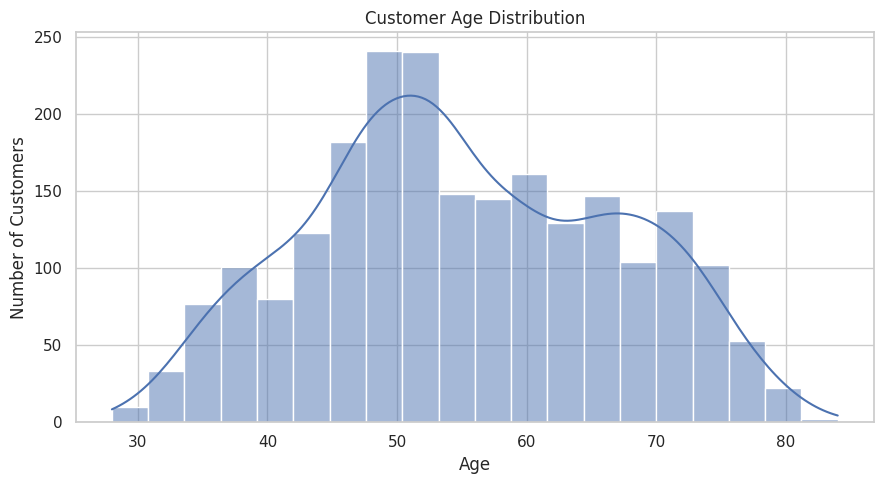

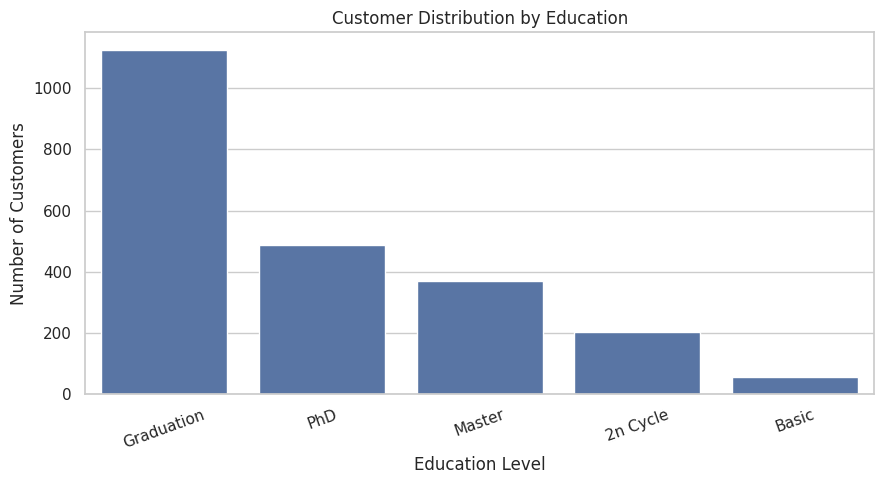

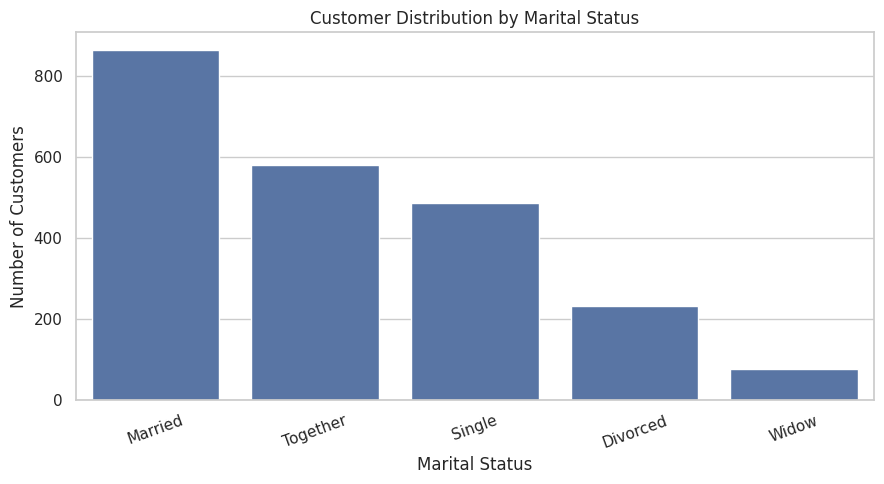

Three demographic charts saved successfully!


In [83]:
# TASK 3 — STEP 3.3: CUSTOMER DEMOGRAPHIC ANALYSIS

# Create folder for charts
CHART_DIR = PROJECT_DIR / "04_Charts_and_Visuals"
CHART_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid")

# CHART 1: Age Distribution
plt.figure(figsize=(9, 5))

sns.histplot(
    data=eda_df,
    x="Age",
    bins=20,
    kde=True
)

plt.title("Customer Age Distribution")
plt.xlabel("Age")
plt.ylabel("Number of Customers")
plt.tight_layout()

plt.savefig(CHART_DIR / "Task3_Chart1_Age_Distribution.png",
            dpi=300, bbox_inches="tight")
plt.show()


# CHART 2: Education Distribution
plt.figure(figsize=(9, 5))

sns.countplot(
    data=eda_df,
    x="Education",
    order=eda_df["Education"].value_counts().index
)

plt.title("Customer Distribution by Education")
plt.xlabel("Education Level")
plt.ylabel("Number of Customers")
plt.xticks(rotation=20)
plt.tight_layout()

plt.savefig(CHART_DIR / "Task3_Chart2_Education_Distribution.png",
            dpi=300, bbox_inches="tight")
plt.show()


# CHART 3: Marital Status Distribution
plt.figure(figsize=(9, 5))

sns.countplot(
    data=eda_df,
    x="Marital_Status",
    order=eda_df["Marital_Status"].value_counts().index
)

plt.title("Customer Distribution by Marital Status")
plt.xlabel("Marital Status")
plt.ylabel("Number of Customers")
plt.xticks(rotation=20)
plt.tight_layout()

plt.savefig(CHART_DIR / "Task3_Chart3_Marital_Status.png",
            dpi=300, bbox_inches="tight")
plt.show()


print("Three demographic charts saved successfully!")

### Observations

1. The age distribution indicates that most customers belong to the 45–55 age range, with the highest concentration around 50–52 years.
2. Graduation is the most common education category among customers, while Basic education has the lowest representation.
3. Married customers form the largest marital-status group, followed by Together and Single. Widow customers represent the smallest group.

These demographic patterns provide an initial understanding of the customer base and can help guide further analysis of spending behaviour and marketing preferences.

## 3.4 Income and Spending Analysis

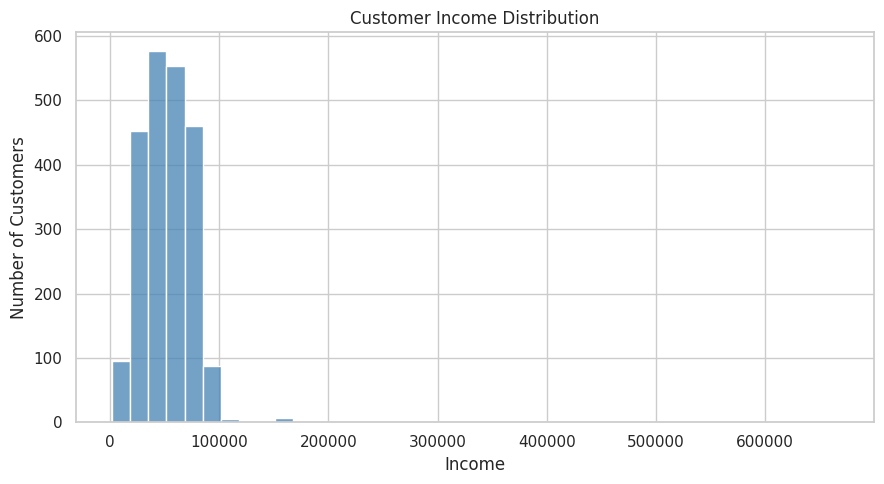

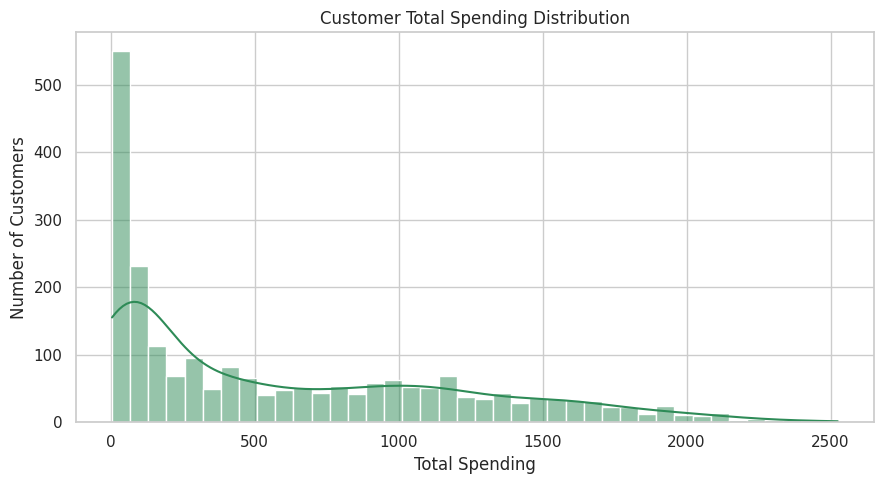

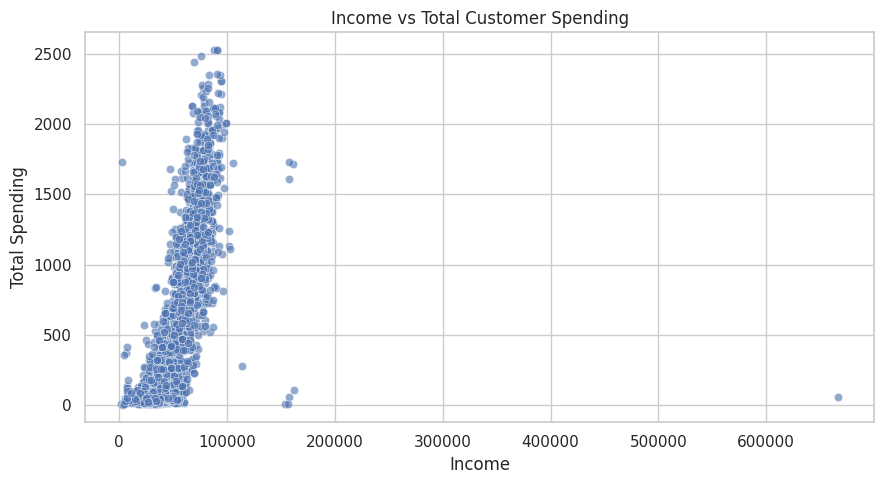

Income and spending charts saved successfully!


In [84]:
# TASK 3 — STEP 3.4: INCOME AND SPENDING ANALYSIS

# CHART 4: Income Distribution
plt.figure(figsize=(9, 5))

sns.histplot(
    data=eda_df,
    x="Income",
    bins=40,
    color="steelblue"
)

plt.title("Customer Income Distribution")
plt.xlabel("Income")
plt.ylabel("Number of Customers")
plt.tight_layout()

plt.savefig(CHART_DIR / "Task3_Chart4_Income_Distribution.png",
            dpi=300, bbox_inches="tight")
plt.show()


# CHART 5: Total Spending Distribution
plt.figure(figsize=(9, 5))

sns.histplot(
    data=eda_df,
    x="TotalSpending",
    bins=40,
    kde=True,
    color="seagreen"
)

plt.title("Customer Total Spending Distribution")
plt.xlabel("Total Spending")
plt.ylabel("Number of Customers")
plt.tight_layout()

plt.savefig(CHART_DIR / "Task3_Chart5_Total_Spending.png",
            dpi=300, bbox_inches="tight")
plt.show()


# CHART 6: Income vs Total Spending
plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=eda_df,
    x="Income",
    y="TotalSpending",
    alpha=0.6
)

plt.title("Income vs Total Customer Spending")
plt.xlabel("Income")
plt.ylabel("Total Spending")
plt.tight_layout()

plt.savefig(CHART_DIR / "Task3_Chart6_Income_vs_Spending.png",
            dpi=300, bbox_inches="tight")
plt.show()


print("Income and spending charts saved successfully!")

### Observations

1. The income distribution shows that most customers have incomes between approximately 30,000 and 90,000. A few unusually high income values create a long right tail.
2. Total customer spending is positively skewed. Most customers have relatively low spending, while a smaller group accounts for higher spending values.
3. The income-versus-spending scatter plot indicates a generally positive relationship between income and total spending. However, some extreme income observations are present and should be considered during interpretation.

These findings provide an initial understanding of customer income and spending behaviour. Further analysis is required to understand product preferences and purchasing patterns.

## 3.5 Product Category Spending Analysis

,Total_Spending,Average_Spending_Per_Customer
MntWines,680816,303.94
MntMeatProducts,373968,166.95
MntGoldProds,98609,44.02
MntFishProducts,84057,37.53
MntSweetProducts,60621,27.06
MntFruits,58917,26.30


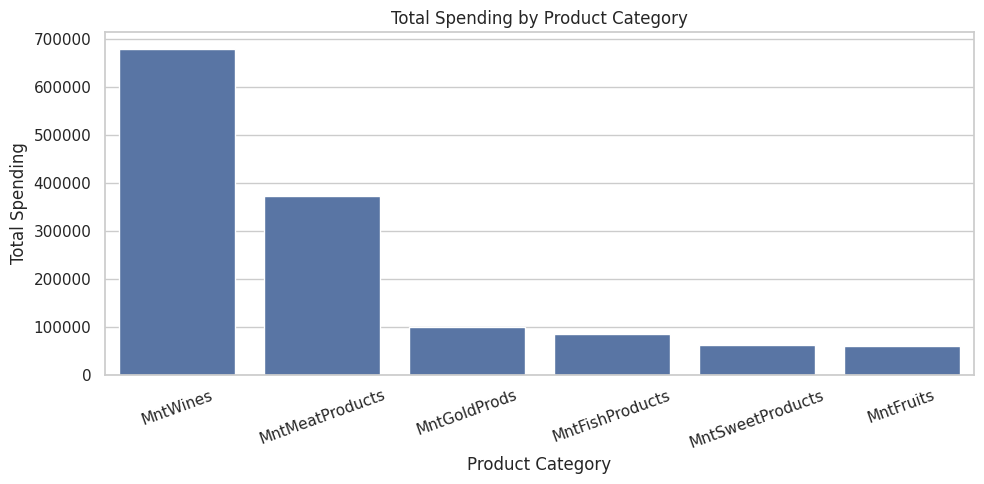

Product category analysis saved successfully!


In [85]:
# TASK 3 — STEP 3.5: PRODUCT CATEGORY SPENDING ANALYSIS

product_cols = [
    "MntWines",
    "MntFruits",
    "MntMeatProducts",
    "MntFishProducts",
    "MntSweetProducts",
    "MntGoldProds"
]

# Calculate total and average spending for each product
product_summary = pd.DataFrame({
    "Total_Spending": eda_df[product_cols].sum(),
    "Average_Spending_Per_Customer": eda_df[product_cols].mean()
})

# Sort by total spending
product_summary = product_summary.sort_values(
    by="Total_Spending",
    ascending=False
)

display(product_summary.round(2))

# CHART 7: Total Spending by Product Category
plt.figure(figsize=(10, 5))

sns.barplot(
    x=product_summary.index,
    y=product_summary["Total_Spending"]
)

plt.title("Total Spending by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Spending")
plt.xticks(rotation=20)
plt.tight_layout()

plt.savefig(
    CHART_DIR / "Task3_Chart7_Product_Category_Spending.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Save product summary
product_summary.to_csv(
    REPORT_DIR / "Task3_Product_Category_Summary.csv"
)

print("Product category analysis saved successfully!")

### Observations

1. Wines generate the highest total customer spending, with a value of 680,816, making them the leading product category.
2. Meat products rank second, with total spending of 373,968.
3. Gold products, fish products and sweet products contribute comparatively lower spending.
4. Fruits have the lowest total spending, at 58,917.
5. The average spending per customer is highest for wines (303.94), followed by meat products (166.95).

These findings indicate that wines and meat products are the strongest product categories in terms of customer spending. Marketing strategies could explore opportunities to retain customers in these categories and increase engagement with lower-spending categories.

## 3.6 Purchase Channel Analysis

,Total_Purchases,Average_Purchases_Per_Customer
NumStorePurchases,12970,5.79
NumWebPurchases,9150,4.08
NumCatalogPurchases,5963,2.66


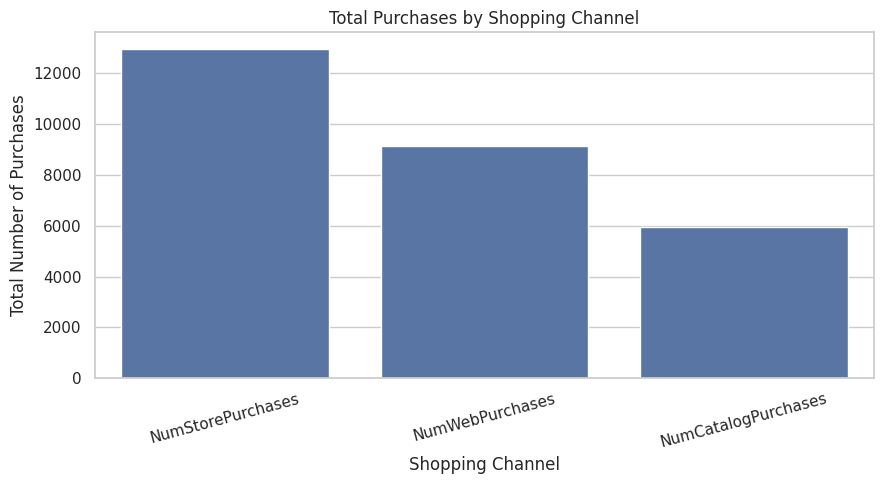

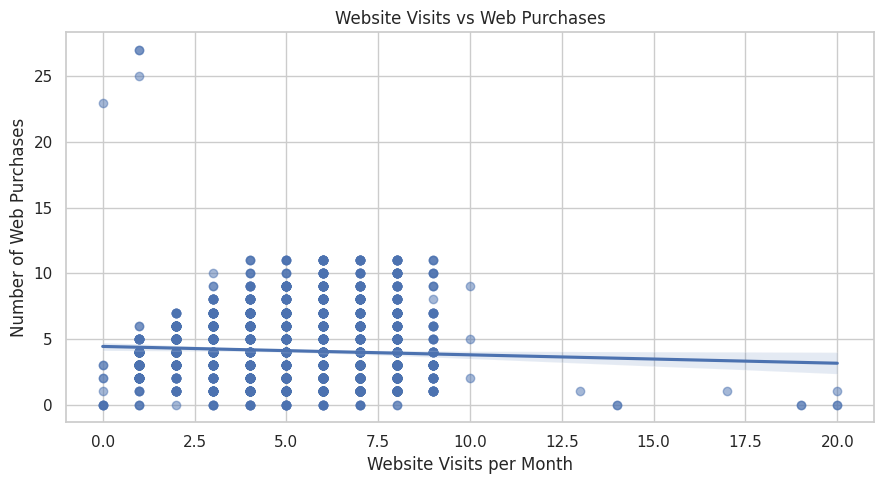

Purchase channel analysis saved successfully!


In [86]:
# TASK 3 — STEP 3.6: PURCHASE CHANNEL ANALYSIS

channel_cols = [
    "NumWebPurchases",
    "NumCatalogPurchases",
    "NumStorePurchases"
]

# Calculate total and average purchases by channel
channel_summary = pd.DataFrame({
    "Total_Purchases": eda_df[channel_cols].sum(),
    "Average_Purchases_Per_Customer": eda_df[channel_cols].mean()
})

channel_summary = channel_summary.sort_values(
    by="Total_Purchases",
    ascending=False
)

display(channel_summary.round(2))


# CHART 8: Total Purchases by Channel
plt.figure(figsize=(9, 5))

sns.barplot(
    x=channel_summary.index,
    y=channel_summary["Total_Purchases"]
)

plt.title("Total Purchases by Shopping Channel")
plt.xlabel("Shopping Channel")
plt.ylabel("Total Number of Purchases")
plt.xticks(rotation=15)
plt.tight_layout()

plt.savefig(
    CHART_DIR / "Task3_Chart8_Purchases_by_Channel.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# CHART 9: Website Visits vs Web Purchases
plt.figure(figsize=(9, 5))

sns.regplot(
    data=eda_df,
    x="NumWebVisitsMonth",
    y="NumWebPurchases",
    scatter_kws={"alpha": 0.5}
)

plt.title("Website Visits vs Web Purchases")
plt.xlabel("Website Visits per Month")
plt.ylabel("Number of Web Purchases")
plt.tight_layout()

plt.savefig(
    CHART_DIR / "Task3_Chart9_Web_Visits_vs_Purchases.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# Save channel summary
channel_summary.to_csv(
    REPORT_DIR / "Task3_Purchase_Channel_Summary.csv"
)

print("Purchase channel analysis saved successfully!")

### Observations

1. Store purchases represent the most frequently used shopping channel, followed by web purchases and catalogue purchases.
2. The website visits versus web purchases chart shows a slight negative trend, indicating that more website visits do not necessarily result in more web purchases.
3. Some customers visit the website frequently but make very few purchases, suggesting that website engagement does not always lead to conversion.

These findings highlight the importance of improving the effectiveness of the online shopping experience and understanding the factors that influence customer purchases across different channels.

## 3.7 Correlation Analysis

,Age,Income,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,TotalSpending,TotalPurchases,TotalCampaignsAccepted
Age,1.00,0.16,0.02,0.16,0.01,0.03,0.04,0.02,0.06,0.15,0.13,0.14,-0.12,0.11,0.17,-0.01
Income,0.16,1.00,-0.00,0.58,0.43,0.58,0.44,0.44,0.32,0.38,0.59,0.53,-0.55,0.66,0.62,0.29
Recency,0.02,-0.00,1.00,0.02,-0.00,0.02,0.00,0.02,0.02,-0.01,0.03,0.00,-0.02,0.02,0.01,-0.09
MntWines,0.16,0.58,0.02,1.00,0.39,0.56,0.40,0.39,0.39,0.54,0.64,0.64,-0.32,0.89,0.76,0.49
MntFruits,0.01,0.43,-0.00,0.39,1.00,0.54,0.59,0.57,0.39,0.30,0.49,0.46,-0.42,0.61,0.52,0.17
MntMeatProducts,0.03,0.58,0.02,0.56,0.54,1.00,0.57,0.52,0.35,0.29,0.72,0.48,-0.54,0.84,0.62,0.33
MntFishProducts,0.04,0.44,0.00,0.40,0.59,0.57,1.00,0.58,0.42,0.29,0.53,0.46,-0.45,0.64,0.54,0.18
MntSweetProducts,0.02,0.44,0.02,0.39,0.57,0.52,0.58,1.00,0.37,0.35,0.49,0.45,-0.42,0.60,0.54,0.20
MntGoldProds,0.06,0.32,0.02,0.39,0.39,0.35,0.42,0.37,1.00,0.42,0.44,0.38,-0.25,0.52,0.51,0.20
NumWebPurchases,0.15,0.38,-0.01,0.54,0.30,0.29,0.29,0.35,0.42,1.00,0.38,0.50,-0.06,0.52,0.77,0.21


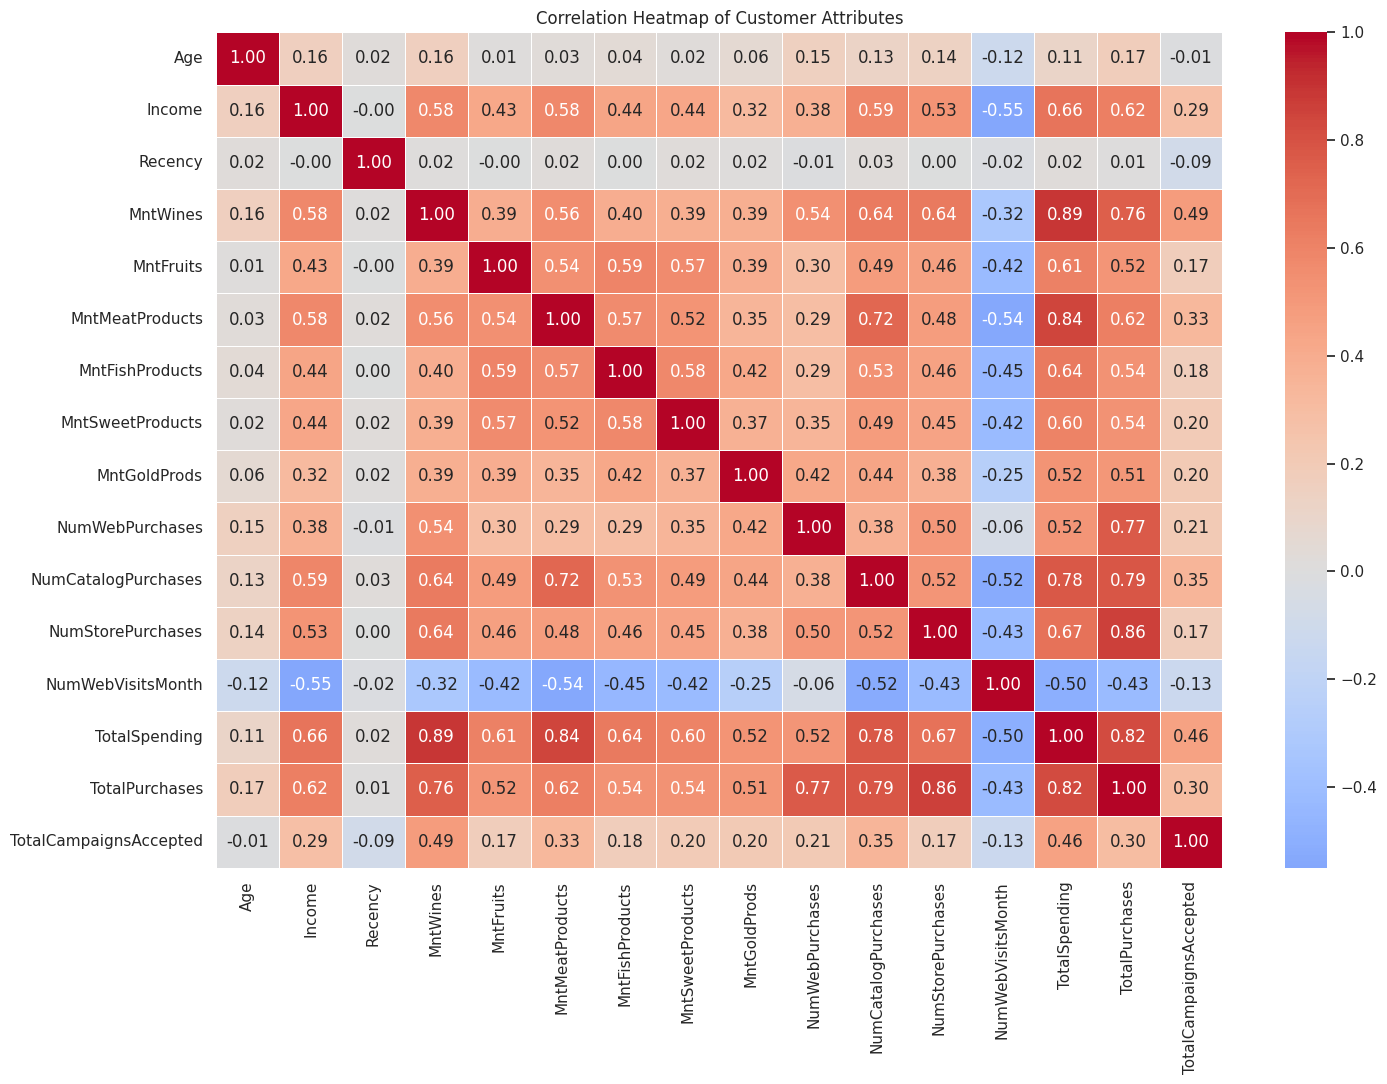

Correlation analysis saved successfully!


In [87]:
# TASK 3 — STEP 3.7: CORRELATION ANALYSIS

# Select relevant numerical variables
correlation_cols = [
    "Age",
    "Income",
    "Recency",
    "MntWines",
    "MntFruits",
    "MntMeatProducts",
    "MntFishProducts",
    "MntSweetProducts",
    "MntGoldProds",
    "NumWebPurchases",
    "NumCatalogPurchases",
    "NumStorePurchases",
    "NumWebVisitsMonth",
    "TotalSpending",
    "TotalPurchases",
    "TotalCampaignsAccepted"
]

# Calculate Pearson correlation matrix
correlation_matrix = eda_df[correlation_cols].corr()

# Display correlation matrix
display(correlation_matrix.round(2))

# Create correlation heatmap
plt.figure(figsize=(15, 11))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5
)

plt.title("Correlation Heatmap of Customer Attributes")
plt.tight_layout()

plt.savefig(
    CHART_DIR / "Task3_Chart10_Correlation_Heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Save correlation matrix
correlation_matrix.to_csv(
    REPORT_DIR / "Task3_Correlation_Matrix.csv"
)

print("Correlation analysis saved successfully!")

### Observations

1. Total spending has a strong positive correlation with wine spending (0.89) and meat product spending (0.84).
2. Income has a positive correlation with total spending (0.66), indicating that higher-income customers tend to spend more.
3. Total purchases have a strong positive correlation with store purchases (0.86) and catalogue purchases (0.79).
4. Website visits have a negative correlation with income (-0.55), total spending (-0.50) and total purchases (-0.43).
5. Recency and age show relatively weak relationships with most purchasing and spending variables.
6. Total campaign acceptance has a moderate positive correlation with total spending (0.46).

Correlation indicates association and does not establish causation. Strong relationships involving derived total variables may also reflect the way those variables are calculated.

## 3.8 EDA Summary and Key Findings

In [88]:
# TASK 3 — STEP 3.8: EDA SUMMARY AND FILE VERIFICATION

eda_findings = [
    "The customer base is concentrated around the 45–55 age group.",
    "Graduation is the most common education category.",
    "Married customers form the largest marital-status group.",
    "Income distribution contains a few unusually high values.",
    "Customer total spending is positively skewed.",
    "Income has a positive correlation with total spending (0.66).",
    "Wines are the highest-spending product category.",
    "Meat products are the second-highest-spending category.",
    "Store purchases are the most frequently used shopping channel.",
    "Website visits do not necessarily translate into more web purchases.",
    "Total spending has a strong correlation with wine spending (0.89).",
    "Recency has weak correlations with most numerical attributes."
]

# Display findings
for i, finding in enumerate(eda_findings, start=1):
    print(f"{i}. {finding}")

# Save EDA findings
eda_summary = pd.DataFrame({
    "Finding_Number": range(1, len(eda_findings) + 1),
    "EDA_Finding": eda_findings
})

eda_summary.to_csv(
    REPORT_DIR / "Task3_EDA_Key_Findings.csv",
    index=False
)

# Verify chart files
chart_files = sorted(CHART_DIR.glob("Task3_Chart*.png"))

print("\nNumber of saved Task 3 charts:", len(chart_files))

for file in chart_files:
    print("✓", file.name)

print("\nEDA summary saved successfully!")

1. The customer base is concentrated around the 45–55 age group.
2. Graduation is the most common education category.
3. Married customers form the largest marital-status group.
4. Income distribution contains a few unusually high values.
5. Customer total spending is positively skewed.
6. Income has a positive correlation with total spending (0.66).
7. Wines are the highest-spending product category.
8. Meat products are the second-highest-spending category.
9. Store purchases are the most frequently used shopping channel.
10. Website visits do not necessarily translate into more web purchases.
11. Total spending has a strong correlation with wine spending (0.89).
12. Recency has weak correlations with most numerical attributes.

Number of saved Task 3 charts: 10
✓ Task3_Chart10_Correlation_Heatmap.png
✓ Task3_Chart1_Age_Distribution.png
✓ Task3_Chart2_Education_Distribution.png
✓ Task3_Chart3_Marital_Status.png
✓ Task3_Chart4_Income_Distribution.png
✓ Task3_Chart5_Total_Spending.png


# TASK 4: CUSTOMER SPENDING ANALYSIS



## 4.1 Spending Across Product Categories

,Total_Spending,Average_Spending,Spending_Share_Percent
MntWines,680816,303.94,50.17
MntMeatProducts,373968,166.95,27.56
MntGoldProds,98609,44.02,7.27
MntFishProducts,84057,37.53,6.19
MntSweetProducts,60621,27.06,4.47
MntFruits,58917,26.30,4.34


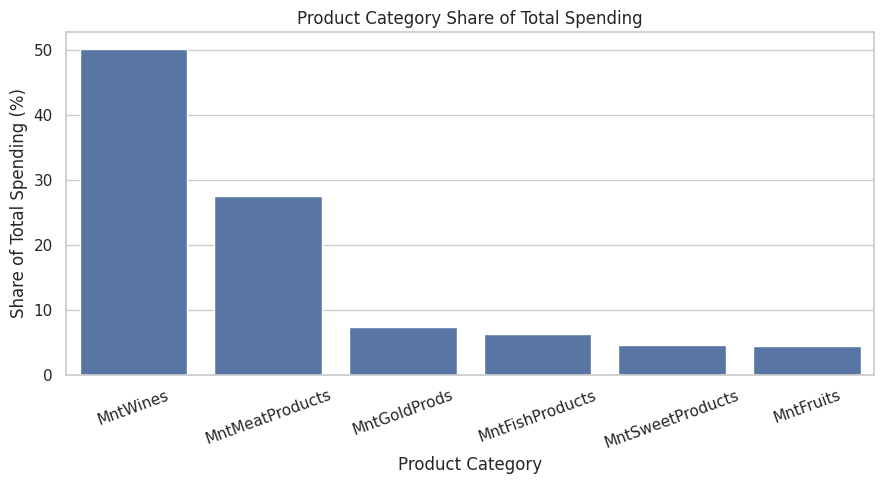

Task 4 Step 4.1 completed and saved!


In [89]:
# TASK 4 — STEP 4.1: SPENDING BY PRODUCT CATEGORY

product_cols = [
    "MntWines",
    "MntFruits",
    "MntMeatProducts",
    "MntFishProducts",
    "MntSweetProducts",
    "MntGoldProds"
]

# Calculate total and average spending
product_analysis = pd.DataFrame({
    "Total_Spending": eda_df[product_cols].sum(),
    "Average_Spending": eda_df[product_cols].mean()
})

# Calculate percentage contribution
product_analysis["Spending_Share_Percent"] = (
    product_analysis["Total_Spending"] /
    product_analysis["Total_Spending"].sum()
) * 100

product_analysis = product_analysis.sort_values(
    by="Total_Spending",
    ascending=False
)

display(product_analysis.round(2))

# Visualize percentage contribution
plt.figure(figsize=(9, 5))

sns.barplot(
    x=product_analysis.index,
    y=product_analysis["Spending_Share_Percent"]
)

plt.title("Product Category Share of Total Spending")
plt.xlabel("Product Category")
plt.ylabel("Share of Total Spending (%)")
plt.xticks(rotation=20)
plt.tight_layout()

plt.savefig(
    CHART_DIR / "Task4_Chart1_Product_Spending_Share.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Save results
product_analysis.to_csv(
    REPORT_DIR / "Task4_Product_Spending_Analysis.csv"
)

print("Task 4 Step 4.1 completed and saved!")

### Observations

1. Wines contribute the largest share of total spending, accounting for 50.17%.
2. Meat products contribute the second-largest share, accounting for 27.56%.
3. Wines and meat products together account for 77.73% of total spending.
4. Fruits contribute the smallest share, at 4.34%.

The results indicate that customer spending is concentrated in wines and meat products. These categories may be important priorities for customer retention and targeted marketing strategies.

## 4.2 Spending Behaviour Across Income Groups

,Customer_Count,Average_Income,Average_Spending,Median_Spending
Income_Group,,,,
Low,560,25296.58,81.93,52.0
Lower-Middle,560,43292.32,239.52,152.5
Upper-Middle,560,59930.91,744.53,731.0
High,560,80450.57,1357.21,1366.0


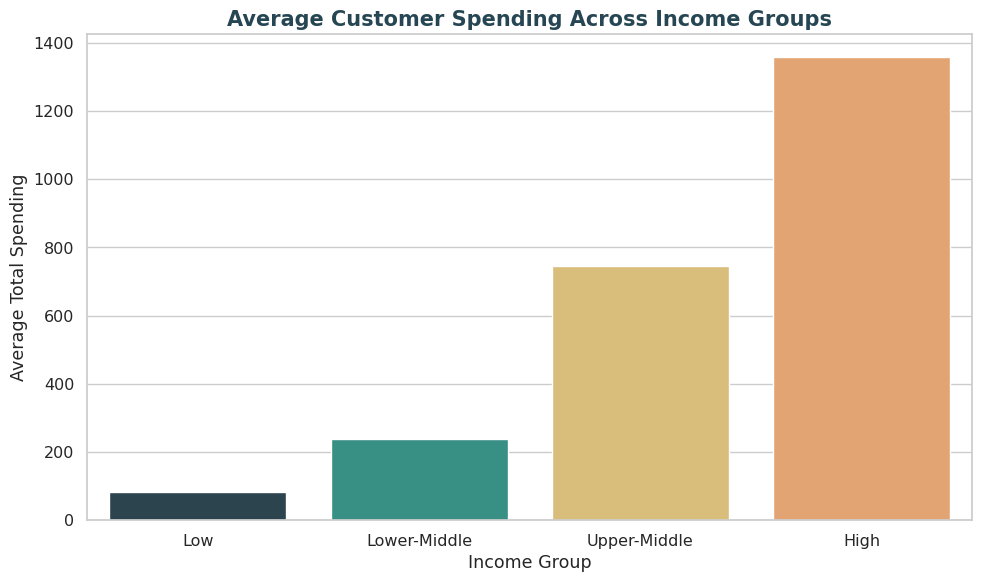

Income group analysis saved successfully!


In [90]:
# TASK 4 — STEP 4.2: INCOME GROUP SPENDING ANALYSIS

# Set the consistent chart theme for Tasks 4–8
chart_palette = [
    "#264653",  # Deep navy
    "#2A9D8F",  # Teal
    "#E9C46A",  # Golden yellow
    "#F4A261",  # Orange
    "#E76F51",  # Coral
    "#8AB17D"   # Sage green
]

sns.set_theme(
    style="whitegrid",
    context="notebook",
    font_scale=1.05
)

# Create income groups using quartiles
spending_df = eda_df.copy()

spending_df["Income_Group"] = pd.qcut(
    spending_df["Income"],
    q=4,
    labels=["Low", "Lower-Middle", "Upper-Middle", "High"]
)

# Calculate spending statistics for each income group
income_group_summary = (
    spending_df.groupby("Income_Group", observed=False)
    .agg(
        Customer_Count=("ID", "count"),
        Average_Income=("Income", "mean"),
        Average_Spending=("TotalSpending", "mean"),
        Median_Spending=("TotalSpending", "median")
    )
    .round(2)
)

display(income_group_summary)

# CHART: Average Spending by Income Group
plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=income_group_summary.reset_index(),
    x="Income_Group",
    y="Average_Spending",
    hue="Income_Group",
    palette=chart_palette[:4],
    legend=False
)

plt.title(
    "Average Customer Spending Across Income Groups",
    fontsize=15,
    fontweight="bold",
    color="#264653"
)
plt.xlabel("Income Group")
plt.ylabel("Average Total Spending")
plt.tight_layout()

plt.savefig(
    CHART_DIR / "Task4_Chart2_Spending_by_Income_Group.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Save summary
income_group_summary.to_csv(
    REPORT_DIR / "Task4_Income_Group_Spending.csv"
)

print("Income group analysis saved successfully!")

### Observations

1. The High income group has the highest average spending of 1,357.21, while the Low income group has the lowest average spending of 81.93.
2. Average customer spending increases consistently with income across all four groups.
3. Each income group contains 560 customers, allowing a balanced comparison.
4. The High income group spends approximately 16.6 times more than the Low income group on average.

The analysis indicates a strong relationship between income level and customer spending. Higher-income customers represent an important target group for premium product offerings and customer retention strategies.

## 4.3 Household Size and Spending Behaviour

,Customer_Count,Average_Spending,Median_Spending,Average_Income
TotalChildren,,,,
0,638,1106.03,1189.5,65591.78
1,1128,472.73,305.0,47757.26
2,421,245.95,93.0,44685.40
3,53,274.60,88.0,47039.98


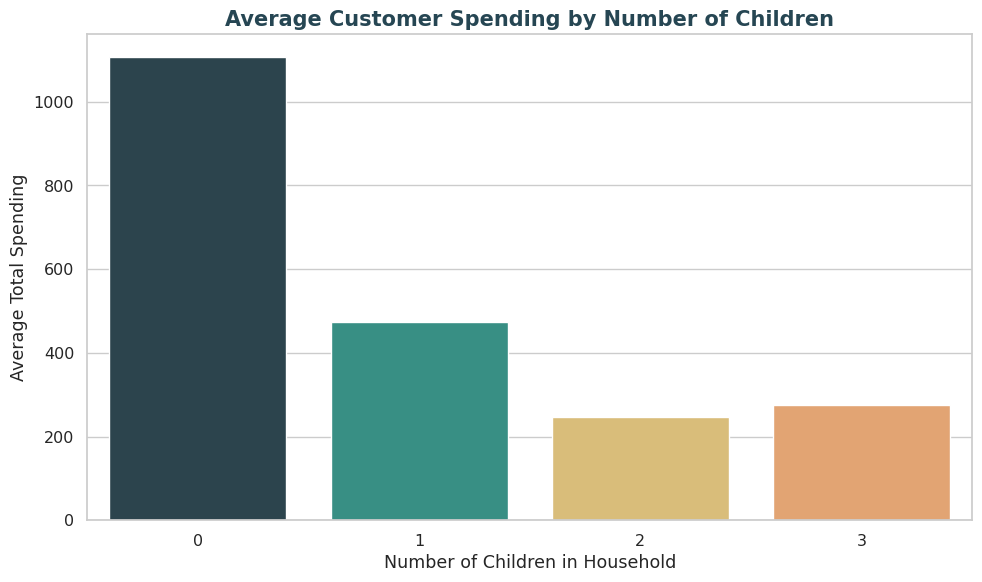

Household spending analysis saved successfully!


In [91]:
# TASK 4 — STEP 4.3: HOUSEHOLD SIZE AND SPENDING

# Group customers by number of children
household_summary = (
    eda_df.groupby("TotalChildren")
    .agg(
        Customer_Count=("ID", "count"),
        Average_Spending=("TotalSpending", "mean"),
        Median_Spending=("TotalSpending", "median"),
        Average_Income=("Income", "mean")
    )
    .round(2)
)

display(household_summary)

# Create colourful chart
plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=household_summary.reset_index(),
    x="TotalChildren",
    y="Average_Spending",
    hue="TotalChildren",
    palette=chart_palette[:4],
    legend=False
)

plt.title(
    "Average Customer Spending by Number of Children",
    fontsize=15,
    fontweight="bold",
    color="#264653"
)
plt.xlabel("Number of Children in Household")
plt.ylabel("Average Total Spending")
plt.tight_layout()

plt.savefig(
    CHART_DIR / "Task4_Chart3_Household_Spending.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Save summary
household_summary.to_csv(
    REPORT_DIR / "Task4_Household_Spending_Analysis.csv"
)

print("Household spending analysis saved successfully!")

### Observations

1. Customers without children have the highest average spending of 1,106.03.
2. Customers with one child spend an average of 472.73, while customers with two children spend 245.95.
3. Customers with three children show a slight increase in average spending compared with customers with two children, but this group contains only 53 customers.
4. The median spending of customers without children is 1,189.50, significantly higher than the other household groups.

The results suggest that household size is associated with customer spending behaviour. Customers without children may have greater disposable income for purchases. However, this is an interpretation rather than a proven explanation, and the relationship may also be influenced by income and other customer characteristics.

## 4.4 High-Spending and Low-Spending Customer Profiles

,Age,Income,TotalChildren,TotalSpending,TotalPurchases,TotalCampaignsAccepted,MntWines,MntMeatProducts
Spending_Group,,,,,,,,
High Spenders,55.99,75061.14,0.38,1490.48,19.99,1.07,739.27,456.79
Low Spenders,52.07,32599.39,1.30,39.26,4.31,0.13,14.01,9.73


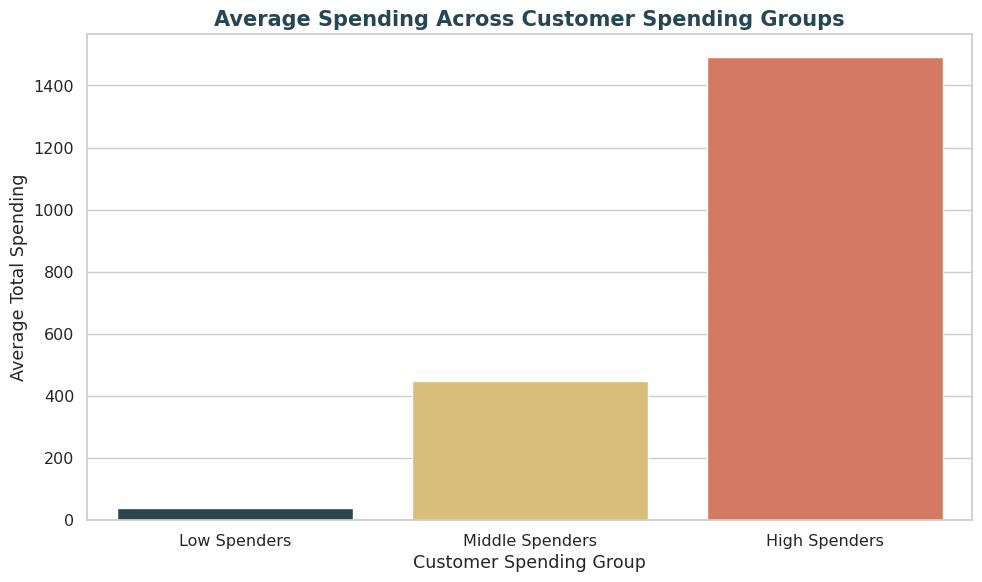

High and low spending customer profiles saved successfully!

Lower quartile threshold: 68.75
Upper quartile threshold: 1045.50


In [92]:
# TASK 4 — STEP 4.4: CUSTOMER SPENDING PROFILES

# Calculate spending quartiles
q1 = eda_df["TotalSpending"].quantile(0.25)
q3 = eda_df["TotalSpending"].quantile(0.75)

# Assign spending groups
profile_df = eda_df.copy()

profile_df["Spending_Group"] = np.select(
    [
        profile_df["TotalSpending"] <= q1,
        profile_df["TotalSpending"] >= q3
    ],
    [
        "Low Spenders",
        "High Spenders"
    ],
    default="Middle Spenders"
)

# Compare low and high spending customers
profile_cols = [
    "Age",
    "Income",
    "TotalChildren",
    "TotalSpending",
    "TotalPurchases",
    "TotalCampaignsAccepted",
    "MntWines",
    "MntMeatProducts"
]

profile_summary = (
    profile_df[
        profile_df["Spending_Group"].isin(
            ["Low Spenders", "High Spenders"]
        )
    ]
    .groupby("Spending_Group")[
        profile_cols
    ]
    .mean()
    .round(2)
)

display(profile_summary)

# Visualize average spending comparison
profile_chart_data = (
    profile_df.groupby("Spending_Group", observed=False)
    ["TotalSpending"]
    .mean()
    .reindex(["Low Spenders", "Middle Spenders", "High Spenders"])
    .reset_index()
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=profile_chart_data,
    x="Spending_Group",
    y="TotalSpending",
    hue="Spending_Group",
    palette=["#264653", "#E9C46A", "#E76F51"],
    legend=False
)

plt.title(
    "Average Spending Across Customer Spending Groups",
    fontsize=15,
    fontweight="bold",
    color="#264653"
)
plt.xlabel("Customer Spending Group")
plt.ylabel("Average Total Spending")
plt.tight_layout()

plt.savefig(
    CHART_DIR / "Task4_Chart4_Spending_Group_Comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Save results
profile_summary.to_csv(
    REPORT_DIR / "Task4_Customer_Spending_Profiles.csv"
)

print("High and low spending customer profiles saved successfully!")
print(f"\nLower quartile threshold: {q1:.2f}")
print(f"Upper quartile threshold: {q3:.2f}")

### Observations

1. High spenders have an average income of 75,061.14, compared with 32,599.39 for low spenders.
2. High spenders make an average of 19.99 purchases, while low spenders make only 4.31.
3. High spenders accept more marketing campaigns on average (1.07) than low spenders (0.13).
4. High spenders have fewer children on average (0.38) than low spenders (1.30).
5. Wine and meat products contribute substantially to the spending of high-value customers.

The analysis indicates that high-spending customers are an important customer group for retention and targeted marketing. Their characteristics can help the business develop more personalized promotional strategies.

## 4.5 Customer Spending Analysis Summary

In [93]:
# TASK 4 — STEP 4.5: SUMMARY AND VERIFICATION

task4_findings = [
    "Wines contribute 50.17% of total customer spending.",
    "Meat products contribute 27.56% of total customer spending.",
    "Wines and meat products together contribute 77.73% of total spending.",
    "Average spending increases across the four income groups.",
    "The high-income group has the highest average spending of 1357.21.",
    "Customers without children have the highest average spending of 1106.03.",
    "High spenders have an average income of 75061.14.",
    "High spenders make an average of 19.99 purchases compared with 4.31 for low spenders.",
    "High spenders accept more campaigns on average than low spenders."
]

for i, finding in enumerate(task4_findings, start=1):
    print(f"{i}. {finding}")

# Save findings
task4_summary = pd.DataFrame({
    "Finding_Number": range(1, len(task4_findings) + 1),
    "Key_Finding": task4_findings
})

task4_summary.to_csv(
    REPORT_DIR / "Task4_Spending_Analysis_Key_Findings.csv",
    index=False
)

# Verify Task 4 charts
task4_charts = sorted(CHART_DIR.glob("Task4_Chart*.png"))

print("\nNumber of Task 4 charts:", len(task4_charts))

for file in task4_charts:
    print("✓", file.name)

print("\nTask 4 summary saved successfully!")

1. Wines contribute 50.17% of total customer spending.
2. Meat products contribute 27.56% of total customer spending.
3. Wines and meat products together contribute 77.73% of total spending.
4. Average spending increases across the four income groups.
5. The high-income group has the highest average spending of 1357.21.
6. Customers without children have the highest average spending of 1106.03.
7. High spenders have an average income of 75061.14.
8. High spenders make an average of 19.99 purchases compared with 4.31 for low spenders.
9. High spenders accept more campaigns on average than low spenders.

Number of Task 4 charts: 4
✓ Task4_Chart1_Product_Spending_Share.png
✓ Task4_Chart2_Spending_by_Income_Group.png
✓ Task4_Chart3_Household_Spending.png
✓ Task4_Chart4_Spending_Group_Comparison.png

Task 4 summary saved successfully!


# TASK 5: MARKETING CAMPAIGN ANALYSIS

## 5.1 Campaign Acceptance Rates

,Accepted_Customers,Acceptance_Rate_Percent
Campaign,,
Campaign 1,144,6.43
Campaign 2,30,1.34
Campaign 3,163,7.28
Campaign 4,167,7.46
Campaign 5,163,7.28
Most Recent Campaign,334,14.91


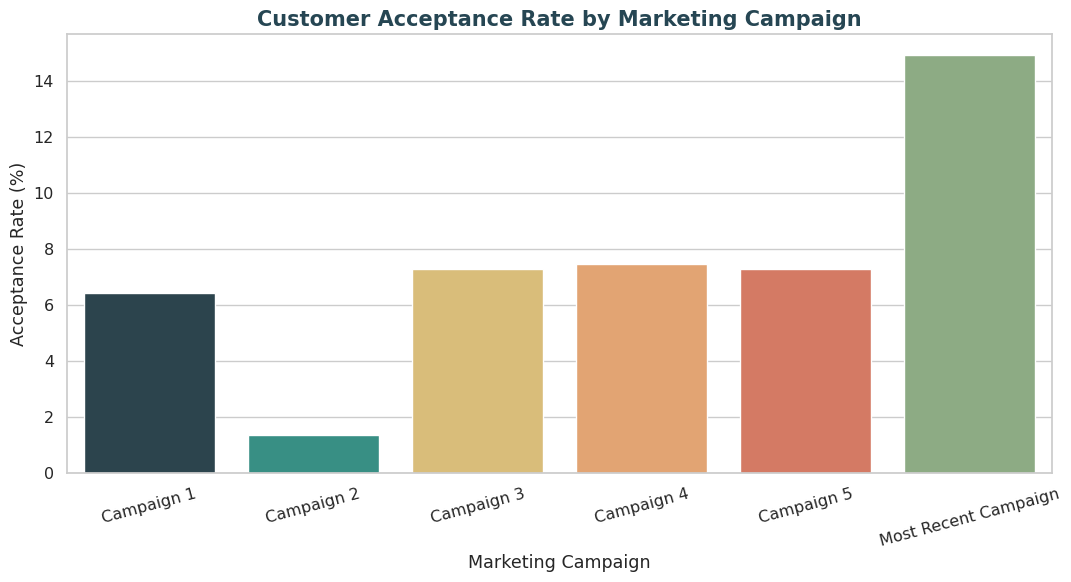

Campaign acceptance analysis saved successfully!


In [94]:
# TASK 5 — STEP 5.1: CAMPAIGN ACCEPTANCE RATES

campaign_cols = [
    "AcceptedCmp1",
    "AcceptedCmp2",
    "AcceptedCmp3",
    "AcceptedCmp4",
    "AcceptedCmp5",
    "Response"
]

campaign_labels = {
    "AcceptedCmp1": "Campaign 1",
    "AcceptedCmp2": "Campaign 2",
    "AcceptedCmp3": "Campaign 3",
    "AcceptedCmp4": "Campaign 4",
    "AcceptedCmp5": "Campaign 5",
    "Response": "Most Recent Campaign"
}

# Calculate acceptance counts and rates
campaign_summary = pd.DataFrame({
    "Accepted_Customers": eda_df[campaign_cols].sum(),
    "Acceptance_Rate_Percent": eda_df[campaign_cols].mean() * 100
})

campaign_summary.index = campaign_summary.index.map(campaign_labels)
campaign_summary.index.name = "Campaign"

campaign_summary = campaign_summary.round(2)

display(campaign_summary)

# Create colourful acceptance-rate chart
plt.figure(figsize=(11, 6))

campaign_plot = campaign_summary.reset_index()

sns.barplot(
    data=campaign_plot,
    x="Campaign",
    y="Acceptance_Rate_Percent",
    hue="Campaign",
    palette=chart_palette,
    legend=False
)

plt.title(
    "Customer Acceptance Rate by Marketing Campaign",
    fontsize=15,
    fontweight="bold",
    color="#264653"
)
plt.xlabel("Marketing Campaign")
plt.ylabel("Acceptance Rate (%)")
plt.xticks(rotation=15)
plt.tight_layout()

plt.savefig(
    CHART_DIR / "Task5_Chart1_Campaign_Acceptance_Rates.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Save campaign summary
campaign_summary.to_csv(
    REPORT_DIR / "Task5_Campaign_Acceptance_Rates.csv"
)

print("Campaign acceptance analysis saved successfully!")

### Observations

1. The most recent marketing campaign achieved the highest acceptance rate of 14.91%.
2. Campaign 2 recorded the lowest acceptance rate of 1.34%.
3. Among the first five campaigns, Campaign 4 performed best with an acceptance rate of 7.46%.
4. The most recent campaign achieved approximately twice the acceptance rate of the best-performing earlier campaign.
5. Acceptance rates vary across campaigns, indicating differences in customer response.

The results suggest that the most recent campaign was more successful than the earlier campaigns. Understanding the customer characteristics associated with campaign acceptance may help improve future marketing strategies.

## 5.2 Customer Characteristics and Campaign Acceptance

,Customer_Count,Average_Income,Average_Age,Average_Spending,Average_Purchases,Average_Campaigns_Accepted
Campaign_Group,,,,,,
Accepted At Least One,609,61680.33,55.69,1001.33,15.80,1.64
Accepted None,1631,48718.64,54.88,458.11,11.32,0.00


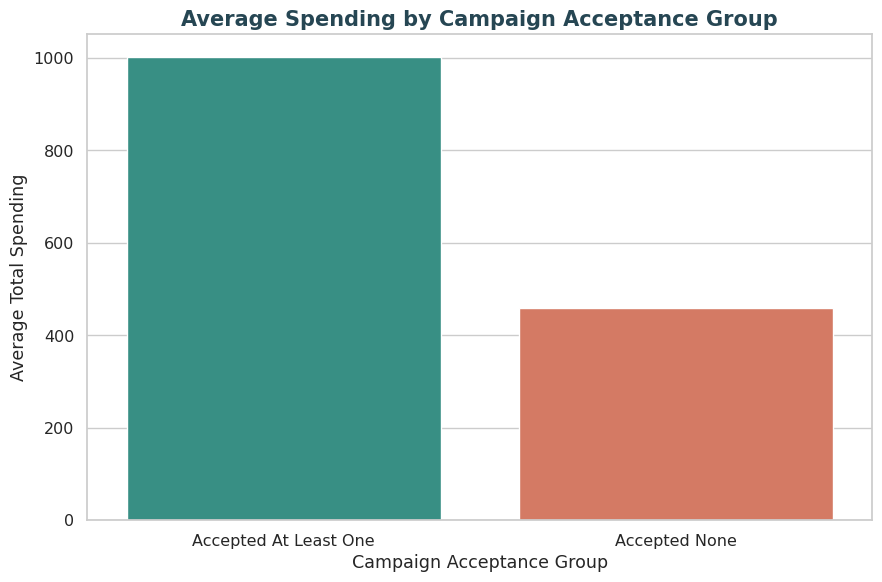

Customer acceptance comparison saved successfully!


In [95]:
# TASK 5 — STEP 5.2: ACCEPTANCE GROUP COMPARISON

# Create customer acceptance groups
campaign_df = eda_df.copy()

campaign_df["Campaign_Group"] = np.where(
    campaign_df["TotalCampaignsAccepted"] > 0,
    "Accepted At Least One",
    "Accepted None"
)

# Compare customer characteristics
acceptance_comparison = (
    campaign_df.groupby("Campaign_Group")
    .agg(
        Customer_Count=("ID", "count"),
        Average_Income=("Income", "mean"),
        Average_Age=("Age", "mean"),
        Average_Spending=("TotalSpending", "mean"),
        Average_Purchases=("TotalPurchases", "mean"),
        Average_Campaigns_Accepted=("TotalCampaignsAccepted", "mean")
    )
    .round(2)
)

display(acceptance_comparison)

# Plot average spending by acceptance group
plt.figure(figsize=(9, 6))

sns.barplot(
    data=acceptance_comparison.reset_index(),
    x="Campaign_Group",
    y="Average_Spending",
    hue="Campaign_Group",
    palette=["#2A9D8F", "#E76F51"],
    legend=False
)

plt.title(
    "Average Spending by Campaign Acceptance Group",
    fontsize=15,
    fontweight="bold",
    color="#264653"
)
plt.xlabel("Campaign Acceptance Group")
plt.ylabel("Average Total Spending")
plt.tight_layout()

plt.savefig(
    CHART_DIR / "Task5_Chart2_Spending_by_Campaign_Acceptance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Save comparison
acceptance_comparison.to_csv(
    REPORT_DIR / "Task5_Customer_Acceptance_Comparison.csv"
)

print("Customer acceptance comparison saved successfully!")

### Observations

1. Customers who accepted at least one campaign have an average spending of 1001.33, compared with 458.11 for customers who accepted none.
2. Campaign-accepting customers spend approximately 2.19 times more on average.
3. The campaign-accepting group has a higher average income of 61680.33.
4. Campaign-accepting customers make an average of 15.80 purchases, compared with 11.32 among non-accepting customers.
5. The average age is similar between the two groups.

The findings indicate a positive association between campaign acceptance and customer spending. However, this analysis does not establish a causal relationship.

## 5.3 Campaign Acceptance Across Customer Demographics

Campaign Acceptance by Education:


,Customer_Count,Accepted_Customers,Acceptance_Rate
Education,,,
2n Cycle,203,46,22.66
Basic,54,7,12.96
Graduation,1127,298,26.44
Master,370,100,27.03
PhD,486,158,32.51



Campaign Acceptance by Marital Status:


,Customer_Count,Accepted_Customers,Acceptance_Rate
Marital_Status,,,
Divorced,232,69,29.74
Married,864,217,25.12
Single,487,151,31.01
Together,580,145,25.00
Widow,77,27,35.06


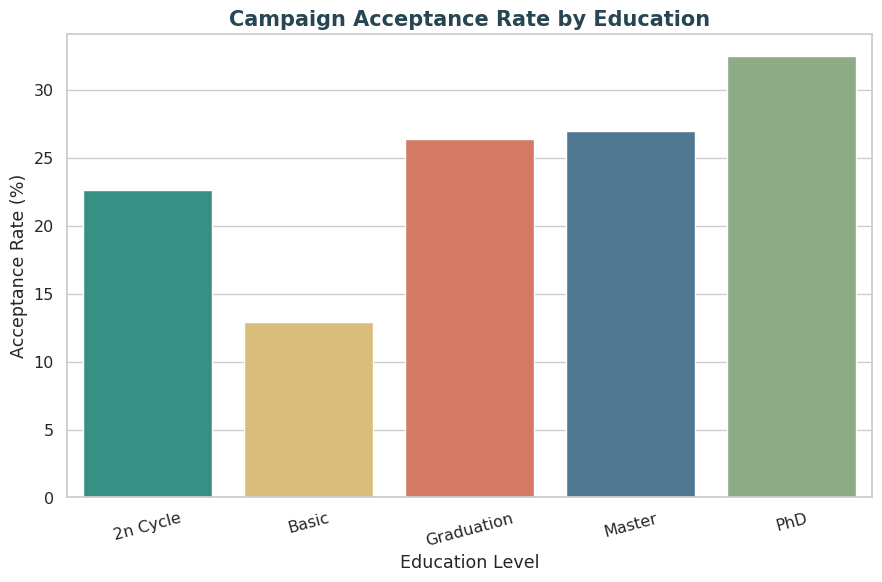

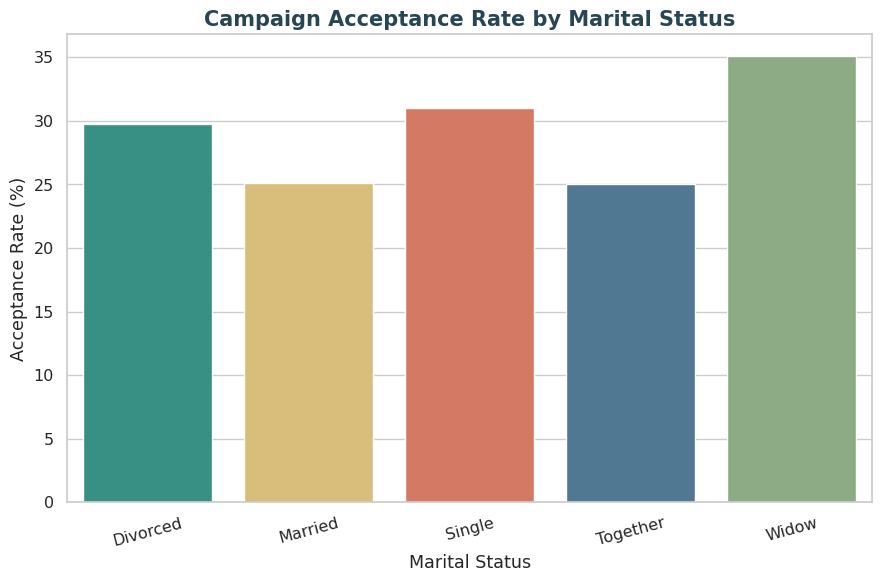

Demographic campaign acceptance analysis saved successfully!


In [96]:
# TASK 5 — STEP 5.3: DEMOGRAPHIC CAMPAIGN ACCEPTANCE

# Create a binary indicator for whether a customer accepted any campaign
campaign_df["Accepted_Any_Campaign"] = (
    campaign_df["TotalCampaignsAccepted"] > 0
).astype(int)

# Calculate acceptance rate by education
education_campaign = (
    campaign_df.groupby("Education")
    .agg(
        Customer_Count=("ID", "count"),
        Accepted_Customers=("Accepted_Any_Campaign", "sum"),
        Acceptance_Rate=("Accepted_Any_Campaign", "mean")
    )
)

education_campaign["Acceptance_Rate"] *= 100
education_campaign = education_campaign.round(2)

# Calculate acceptance rate by marital status
marital_campaign = (
    campaign_df.groupby("Marital_Status")
    .agg(
        Customer_Count=("ID", "count"),
        Accepted_Customers=("Accepted_Any_Campaign", "sum"),
        Acceptance_Rate=("Accepted_Any_Campaign", "mean")
    )
)

marital_campaign["Acceptance_Rate"] *= 100
marital_campaign = marital_campaign.round(2)

print("Campaign Acceptance by Education:")
display(education_campaign)

print("\nCampaign Acceptance by Marital Status:")
display(marital_campaign)

# Plot education acceptance rates
plt.figure(figsize=(9, 6))

sns.barplot(
    data=education_campaign.reset_index(),
    x="Education",
    y="Acceptance_Rate",
    hue="Education",
    palette=["#2A9D8F", "#E9C46A", "#E76F51", "#457B9D", "#8AB17D"],
    legend=False
)

plt.title(
    "Campaign Acceptance Rate by Education",
    fontsize=15,
    fontweight="bold",
    color="#264653"
)
plt.xlabel("Education Level")
plt.ylabel("Acceptance Rate (%)")
plt.xticks(rotation=15)
plt.tight_layout()

plt.savefig(
    CHART_DIR / "Task5_Chart3_Acceptance_by_Education.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Plot marital-status acceptance rates
plt.figure(figsize=(9, 6))

sns.barplot(
    data=marital_campaign.reset_index(),
    x="Marital_Status",
    y="Acceptance_Rate",
    hue="Marital_Status",
    palette=["#2A9D8F", "#E9C46A", "#E76F51", "#457B9D", "#8AB17D"],
    legend=False
)

plt.title(
    "Campaign Acceptance Rate by Marital Status",
    fontsize=15,
    fontweight="bold",
    color="#264653"
)
plt.xlabel("Marital Status")
plt.ylabel("Acceptance Rate (%)")
plt.xticks(rotation=15)
plt.tight_layout()

plt.savefig(
    CHART_DIR / "Task5_Chart4_Acceptance_by_Marital_Status.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Save tables
education_campaign.to_csv(
    REPORT_DIR / "Task5_Acceptance_by_Education.csv"
)

marital_campaign.to_csv(
    REPORT_DIR / "Task5_Acceptance_by_Marital_Status.csv"
)

print("Demographic campaign acceptance analysis saved successfully!")

### Observations

1. PhD customers have the highest campaign acceptance rate at 32.51%.
2. Basic education customers have the lowest acceptance rate at 12.96%.
3. Graduation customers form the largest education group, with 1127 customers.
4. Widow customers show the highest marital-status acceptance rate at 35.06%, although this group contains only 77 customers.
5. Single customers have an acceptance rate of 31.01%.
6. Together customers have the lowest marital-status acceptance rate at 25.00%.

The results indicate differences in campaign acceptance across education and marital-status groups. These patterns may help identify customer groups for targeted marketing. However, the differences do not establish causation, and smaller groups should be interpreted cautiously.

## 5.4 Discount Purchase Behaviour and Campaign Acceptance

Discount Purchase Behaviour by Campaign Acceptance:


,Customer_Count,Average_Deal_Purchases,Median_Deal_Purchases,Total_Deal_Purchases,Average_Total_Purchases
Campaign_Group,,,,,
Accepted At Least One,609,2.22,1.0,1351,15.80
Accepted None,1631,2.36,2.0,3857,11.32


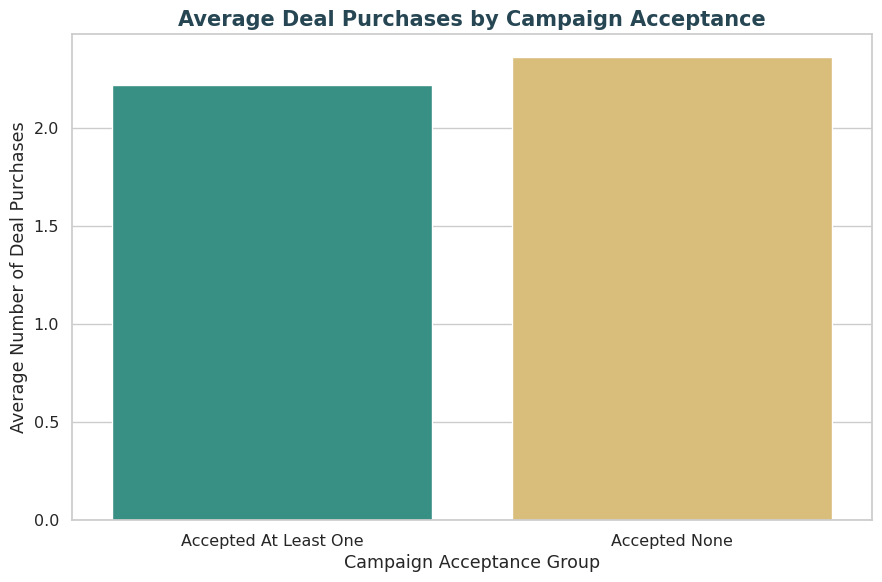

Discount purchase behaviour analysis saved successfully!


In [97]:

# TASK 5 — STEP 5.4: DISCOUNT PURCHASE BEHAVIOUR

# Compare deal purchases between campaign acceptance groups
discount_comparison = (
    campaign_df.groupby("Campaign_Group")
    .agg(
        Customer_Count=("ID", "count"),
        Average_Deal_Purchases=("NumDealsPurchases", "mean"),
        Median_Deal_Purchases=("NumDealsPurchases", "median"),
        Total_Deal_Purchases=("NumDealsPurchases", "sum"),
        Average_Total_Purchases=("TotalPurchases", "mean")
    )
    .round(2)
)

print("Discount Purchase Behaviour by Campaign Acceptance:")
display(discount_comparison)

# Prepare data for plotting
discount_plot = discount_comparison.reset_index()

# Plot average deal purchases
plt.figure(figsize=(9, 6))

sns.barplot(
    data=discount_plot,
    x="Campaign_Group",
    y="Average_Deal_Purchases",
    hue="Campaign_Group",
    palette=["#2A9D8F", "#E9C46A"],
    legend=False
)

plt.title(
    "Average Deal Purchases by Campaign Acceptance",
    fontsize=15,
    fontweight="bold",
    color="#264653"
)
plt.xlabel("Campaign Acceptance Group")
plt.ylabel("Average Number of Deal Purchases")
plt.tight_layout()

plt.savefig(
    CHART_DIR / "Task5_Chart5_Deal_Purchases_by_Acceptance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Save comparison table
discount_comparison.to_csv(
    REPORT_DIR / "Task5_Discount_Purchase_Behaviour.csv"
)

print("Discount purchase behaviour analysis saved successfully!")

### Observations

1. Customers who accepted no campaigns made an average of 2.36 deal purchases, compared with 2.22 among campaign-accepting customers.
2. The median deal purchases were 2 for non-accepting customers and 1 for accepting customers.
3. Campaign-accepting customers made more total purchases on average (15.80 versus 11.32).
4. The non-accepting group recorded more total deal purchases (3857), but it also contains substantially more customers.
5. Campaign acceptance does not necessarily indicate greater reliance on discounts.

The findings suggest that campaign-accepting customers make more purchases overall, but they do not make more deal purchases on average. Therefore, campaign acceptance and discount purchasing should be treated as separate customer behaviours.

## 5.5 Correlation Analysis of Campaign Acceptance

Correlation with Total Campaign Acceptance:


,Correlation_with_Campaign_Acceptance
TotalSpending,0.456
TotalPurchases,0.300
Income,0.287
Age,-0.007
Recency,-0.089
NumDealsPurchases,-0.094
NumWebVisitsMonth,-0.128


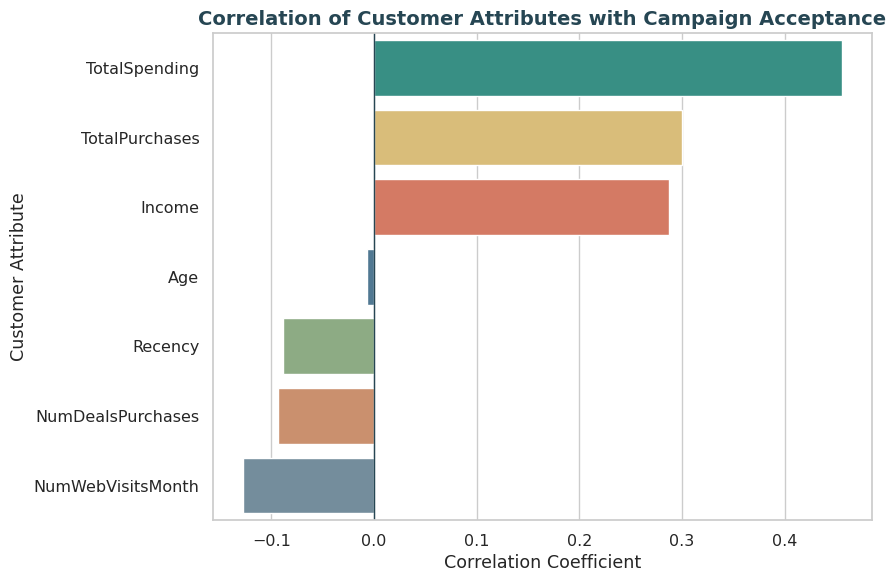

Campaign acceptance correlation analysis saved successfully!


In [98]:
# TASK 5 — STEP 5.5: CAMPAIGN ACCEPTANCE CORRELATION

# Select relevant numerical attributes
campaign_corr_cols = [
    "TotalCampaignsAccepted",
    "Income",
    "Age",
    "Recency",
    "TotalSpending",
    "TotalPurchases",
    "NumDealsPurchases",
    "NumWebVisitsMonth"
]

# Calculate correlations
campaign_correlation = (
    campaign_df[campaign_corr_cols]
    .corr()["TotalCampaignsAccepted"]
    .drop("TotalCampaignsAccepted")
    .sort_values(ascending=False)
    .to_frame("Correlation_with_Campaign_Acceptance")
    .round(3)
)

print("Correlation with Total Campaign Acceptance:")
display(campaign_correlation)

# Plot correlations using the project colour theme
plt.figure(figsize=(9, 6))

sns.barplot(
    data=campaign_correlation.reset_index(),
    x="Correlation_with_Campaign_Acceptance",
    y="index",
    hue="index",
    palette=[
        "#2A9D8F", "#E9C46A", "#E76F51", "#457B9D",
        "#8AB17D", "#D98C5F", "#6D8FA3"
    ],
    legend=False
)

plt.axvline(0, color="#264653", linewidth=1)
plt.title(
    "Correlation of Customer Attributes with Campaign Acceptance",
    fontsize=14,
    fontweight="bold",
    color="#264653"
)
plt.xlabel("Correlation Coefficient")
plt.ylabel("Customer Attribute")
plt.tight_layout()

plt.savefig(
    CHART_DIR / "Task5_Chart6_Campaign_Acceptance_Correlation.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Save correlation table
campaign_correlation.to_csv(
    REPORT_DIR / "Task5_Campaign_Acceptance_Correlation.csv"
)

print("Campaign acceptance correlation analysis saved successfully!")

# TASK 6: SHOPPING CHANNEL ANALYSIS

## 6.1 Purchase Summary by Shopping Channel

In [99]:
# TASK 6 — STEP 6.1: PURCHASE SUMMARY BY CHANNEL

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Consistent project colour theme
PROJECT_PALETTE = [
    "#2F4858",  # Deep navy
    "#3A9188",  # Teal
    "#D9BE7A",  # Mustard
    "#D77A66",  # Coral
    "#8EAD88",  # Sage green
    "#547C96"   # Blue
]

sns.set_theme(style="whitegrid", context="notebook")

# Calculate purchase totals and averages
channel_columns = {
    "Web": "NumWebPurchases",
    "Catalog": "NumCatalogPurchases",
    "Store": "NumStorePurchases"
}

channel_summary = pd.DataFrame({
    "Total_Purchases": {
        channel: eda_df[column].sum()
        for channel, column in channel_columns.items()
    },
    "Average_Purchases_Per_Customer": {
        channel: eda_df[column].mean()
        for channel, column in channel_columns.items()
    }
})

channel_summary["Purchase_Share_Percent"] = (
    channel_summary["Total_Purchases"]
    / channel_summary["Total_Purchases"].sum()
    * 100
)

channel_summary = channel_summary.round(2)

print("Shopping Channel Summary:")
display(channel_summary)

# Save results
REPORT_DIR = PROJECT_DIR / "05_Worksheet_and_Reports"
REPORT_DIR.mkdir(parents=True, exist_ok=True)

channel_summary.to_csv(
    REPORT_DIR / "Task6_Channel_Summary.csv"
)

print("Channel summary saved successfully!")

Shopping Channel Summary:


,Total_Purchases,Average_Purchases_Per_Customer,Purchase_Share_Percent
Web,9150,4.08,32.58
Catalog,5963,2.66,21.23
Store,12970,5.79,46.18


Channel summary saved successfully!


### Observations

1. Store purchases account for the highest share of total purchases at 46.18%.
2. Web purchases contribute 32.58% of total purchases, making them the second most-used shopping channel.
3. Catalog purchases account for the lowest share at 21.23%.
4. Customers make an average of 5.79 store purchases, 4.08 web purchases, and 2.66 catalog purchases.
5. These results indicate that physical stores are the most preferred shopping channel among the customers.

## 6.2 Shopping Channel Preference Visualization

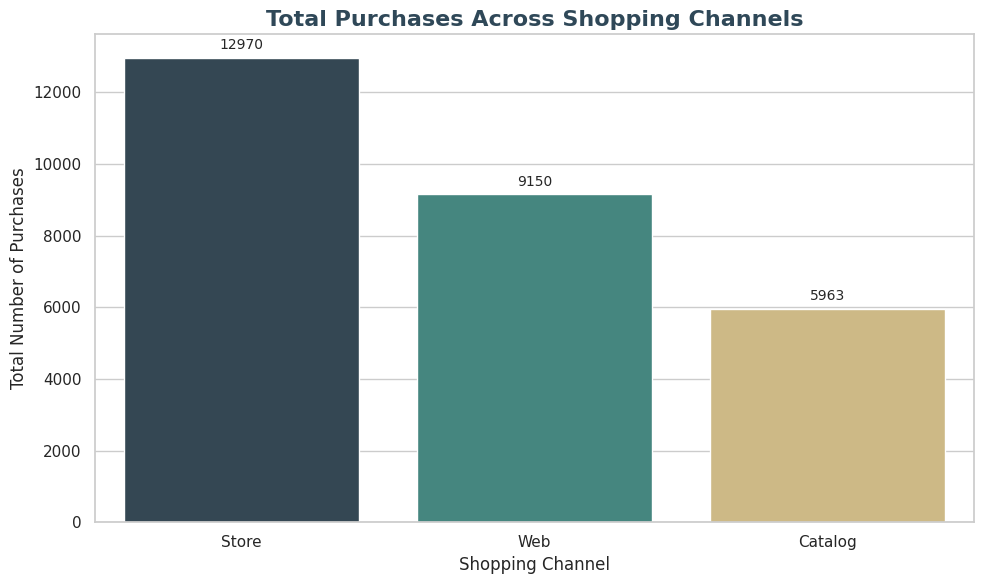

Channel preference chart saved successfully!


In [100]:
# TASK 6 — STEP 6.2: CHANNEL PREFERENCE CHART

import matplotlib.pyplot as plt
import seaborn as sns

# Consistent project colour theme
PROJECT_PALETTE = [
    "#2F4858",  # Deep navy
    "#3A9188",  # Teal
    "#D9BE7A",  # Mustard
    "#D77A66",  # Coral
    "#8EAD88",  # Sage green
    "#547C96"   # Blue
]

sns.set_theme(style="whitegrid", context="notebook")

# Prepare chart data
plot_data = channel_summary.sort_values(
    "Total_Purchases", ascending=False
).reset_index()

plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=plot_data,
    x="index",
    y="Total_Purchases",
    hue="index",
    palette=PROJECT_PALETTE[:3],
    legend=False
)

# Add value labels
for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=4, fontsize=10)

plt.title(
    "Total Purchases Across Shopping Channels",
    fontsize=16,
    fontweight="bold",
    color="#2F4858"
)
plt.xlabel("Shopping Channel", fontsize=12)
plt.ylabel("Total Number of Purchases", fontsize=12)
plt.tight_layout()

# Save chart
CHART_DIR = PROJECT_DIR / "04_Charts_and_Visuals"
CHART_DIR.mkdir(parents=True, exist_ok=True)

plt.savefig(
    CHART_DIR / "Task6_Chart1_Channel_Preferences.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Channel preference chart saved successfully!")

### Observations

1. The visualization shows that stores have the highest number of purchases, with 12,970 transactions.
2. Web purchases rank second, with 9,150 transactions.
3. Catalog purchases have the lowest number of transactions, with 5,963.
4. The chart clearly highlights the stronger preference for store shopping compared with web and catalog shopping.
5. The company should maintain its store presence while exploring opportunities to improve online and catalog sales.

## 6.3 Website Visits and Web Purchase Behaviour

In [101]:
# TASK 6 — STEP 6.3: WEBSITE VISITS VS WEB PURCHASES

# Calculate relationship between website visits and web purchases
web_correlation = eda_df[
    ["NumWebVisitsMonth", "NumWebPurchases"]
].corr().iloc[0, 1]

# Group customers by monthly website visits
visits_summary = (
    eda_df.groupby("NumWebVisitsMonth")
    .agg(
        Customer_Count=("ID", "count"),
        Average_Web_Purchases=("NumWebPurchases", "mean")
    )
    .reset_index()
    .round(2)
)

print("Website Visits vs Web Purchases:")
display(visits_summary)

print(f"\nCorrelation between website visits and web purchases: {web_correlation:.3f}")

# Save summary
visits_summary.to_csv(
    REPORT_DIR / "Task6_Web_Visits_vs_Purchases.csv",
    index=False
)

print("\nWebsite visit analysis saved successfully!")

Website Visits vs Web Purchases:


,NumWebVisitsMonth,Customer_Count,Average_Web_Purchases
0,0,11,3.09
1,1,153,3.65
2,2,202,4.22
3,3,205,4.51
4,4,218,4.49
5,5,281,4.32
6,6,340,4.27
7,7,393,3.64
8,8,342,3.89
9,9,83,4.29



Correlation between website visits and web purchases: -0.056

Website visit analysis saved successfully!


### Observations

1. Most customers visit the website between 3 and 8 times per month.
2. Average web purchases do not consistently increase with the number of website visits.
3. The correlation between website visits and web purchases is -0.056, indicating a very weak negative relationship.
4. Higher website traffic does not necessarily result in higher web purchases.
5. The company should focus on improving website engagement and converting visitors into actual customers.

## 6.4 Website Visit and Purchase Relationship

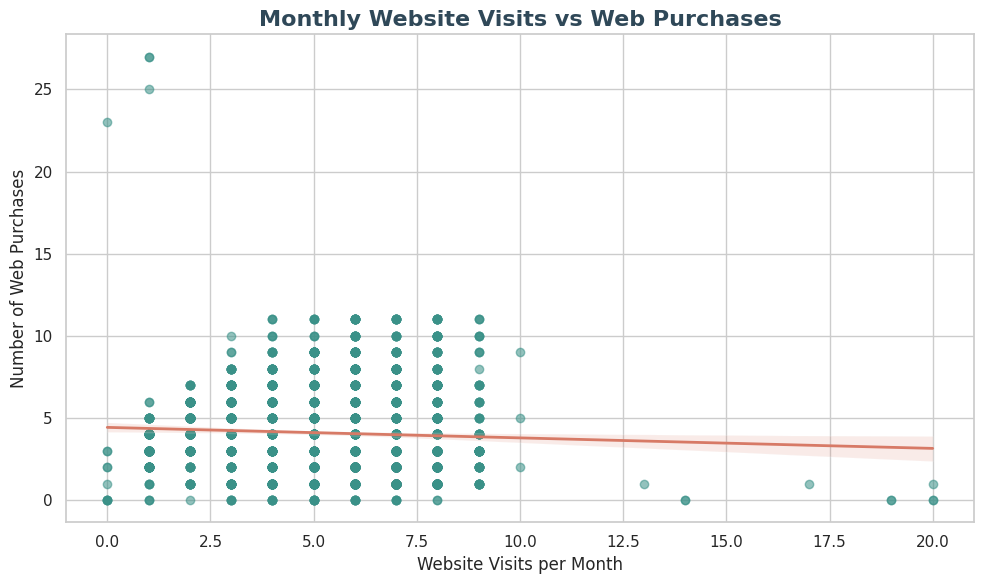

Website visits vs purchases chart saved successfully!


In [102]:
# TASK 6 — STEP 6.4: WEBSITE VISITS VS WEB PURCHASES CHART

plt.figure(figsize=(10, 6))

sns.regplot(
    data=eda_df,
    x="NumWebVisitsMonth",
    y="NumWebPurchases",
    scatter_kws={"alpha": 0.55, "color": "#3A9188"},
    line_kws={"color": "#D77A66", "linewidth": 2},
    color="#D77A66"
)

plt.title(
    "Monthly Website Visits vs Web Purchases",
    fontsize=16,
    fontweight="bold",
    color="#2F4858"
)
plt.xlabel("Website Visits per Month")
plt.ylabel("Number of Web Purchases")

plt.tight_layout()

plt.savefig(
    CHART_DIR / "Task6_Chart2_Web_Visits_vs_Purchases.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Website visits vs purchases chart saved successfully!")

### Observations

1. The scatter plot shows a widely distributed relationship between monthly website visits and web purchases.
2. The trend line indicates a slight negative relationship between website visits and web purchases.
3. The correlation coefficient of -0.056 confirms that the relationship is very weak.
4. Customers who visit the website more frequently do not necessarily make more purchases.
5. The company should investigate factors affecting website conversion, such as product availability, navigation, pricing, and checkout experience.

## 6.5 Shopping Channel Preferences Across Income Groups

In [103]:
# TASK 6 — STEP 6.5: CHANNEL PREFERENCES BY INCOME GROUP

# Create four income groups using quartiles
eda_df["Income_Group"] = pd.qcut(
    eda_df["Income"],
    q=4,
    labels=["Low", "Lower-Middle", "Upper-Middle", "High"]
)

# Calculate average purchases by channel for each income group
income_channel_summary = (
    eda_df.groupby("Income_Group", observed=False)
    .agg(
        Customer_Count=("ID", "count"),
        Average_Web_Purchases=("NumWebPurchases", "mean"),
        Average_Catalog_Purchases=("NumCatalogPurchases", "mean"),
        Average_Store_Purchases=("NumStorePurchases", "mean")
    )
    .round(2)
)

print("Shopping Channel Preferences by Income Group:")
display(income_channel_summary)

# Save results
income_channel_summary.to_csv(
    REPORT_DIR / "Task6_Channel_Preferences_by_Income.csv"
)

print("Income group channel analysis saved successfully!")

Shopping Channel Preferences by Income Group:


,Customer_Count,Average_Web_Purchases,Average_Catalog_Purchases,Average_Store_Purchases
Income_Group,,,,
Low,560,2.02,0.47,2.97
Lower-Middle,560,3.40,1.21,4.23
Upper-Middle,560,5.61,3.26,7.61
High,560,5.31,5.71,8.35


Income group channel analysis saved successfully!


### Observations

1. The analysis shows that average purchases across web, catalog, and store channels generally increase with customer income.
2. The low-income group has the lowest average purchases across all three channels, with 2.02 web, 0.47 catalog, and 2.97 store purchases.
3. The high-income group records the highest average store purchases at 8.35 and catalog purchases at 5.71.
4. The upper-middle-income group records the highest average web purchases at 5.61, slightly higher than the high-income group's 5.31.
5. Store purchases are the most preferred channel for the low, lower-middle, and upper-middle-income groups.
6. High-income customers show a stronger preference for store and catalog shopping compared with web shopping.
7. The company can use these findings to develop income-based marketing strategies and personalized offers across different shopping channels.

# TASK 7: CUSTOMER SEGMENTATION ANALYSIS

## 7.1 Preparing Data for Customer Segmentation

In [104]:
# TASK 7 — STEP 7.1: PREPARE SEGMENTATION DATA

# Select important customer attributes for segmentation
segmentation_features = [
    "Income",
    "TotalSpending",
    "TotalPurchases",
    "TotalChildren",
    "Age",
    "Recency",
    "NumWebVisitsMonth"
]

# Create a separate dataset for clustering
segment_df = eda_df[segmentation_features].copy()

# Check missing values
print("Missing values in segmentation features:")
display(segment_df.isna().sum().to_frame("Missing_Count"))

# Check dataset dimensions
print("\nSegmentation dataset shape:")
print(segment_df.shape)

# Display first five records
print("\nFirst five records:")
display(segment_df.head())

# Check descriptive statistics
print("\nFeature summary:")
display(segment_df.describe().round(2))

# Verify readiness
if segment_df.isna().sum().sum() == 0:
    print("\nSegmentation data is ready for scaling.")
else:
    print("\nMissing values detected. Further preparation is required.")

Missing values in segmentation features:


,Missing_Count
Income,0
TotalSpending,0
TotalPurchases,0
TotalChildren,0
Age,3
Recency,0
NumWebVisitsMonth,0



Segmentation dataset shape:
(2240, 7)

First five records:


,Income,TotalSpending,TotalPurchases,TotalChildren,Age,Recency,NumWebVisitsMonth
0,58138.0,1617,22,0,67.0,58,7
1,46344.0,27,4,2,70.0,38,5
2,71613.0,776,20,0,59.0,26,4
3,26646.0,53,6,1,40.0,26,6
4,58293.0,422,14,1,43.0,94,5



Feature summary:


,Income,TotalSpending,TotalPurchases,TotalChildren,Age,Recency,NumWebVisitsMonth
count,2240.00,2240.00,2240.00,2240.00,2237.0,2240.00,2240.00
mean,52242.59,605.80,12.54,0.95,55.1,49.11,5.32
std,25039.06,602.25,7.21,0.75,11.7,28.96,2.43
min,1730.00,5.00,0.00,0.00,28.0,0.00,0.00
25%,35538.75,68.75,6.00,0.00,47.0,24.00,3.00
50%,51498.50,396.00,12.00,1.00,54.0,49.00,6.00
75%,68289.75,1045.50,18.00,1.00,65.0,74.00,7.00
max,666666.00,2525.00,32.00,3.00,84.0,99.00,20.00



Missing values detected. Further preparation is required.


## 7.2 Feature Scaling

In [105]:
# TASK 7 — STEP 7.2: FEATURE SCALING

from sklearn.preprocessing import StandardScaler

# Exclude records with missing Age for clustering
segmentation_data = eda_df.loc[
    eda_df[segmentation_features].notna().all(axis=1),
    ["ID"] + segmentation_features
].copy()

# Select features for clustering
segment_df = segmentation_data[segmentation_features].copy()

# Initialize StandardScaler
scaler = StandardScaler()

# Scale all selected features
scaled_features = scaler.fit_transform(segment_df)

# Convert scaled features into a DataFrame
scaled_df = pd.DataFrame(
    scaled_features,
    columns=segmentation_features,
    index=segment_df.index
)

print("Feature scaling completed successfully!")
print("\nScaled dataset shape:", scaled_df.shape)

print("\nScaled feature summary:")
display(scaled_df.describe().round(2))

print("\nMean of scaled features:")
display(scaled_df.mean().round(2))

print("\nStandard deviation of scaled features:")
display(scaled_df.std().round(2))

Feature scaling completed successfully!

Scaled dataset shape: (2237, 7)

Scaled feature summary:


,Income,TotalSpending,TotalPurchases,TotalChildren,Age,Recency,NumWebVisitsMonth
count,2237.00,2237.00,2237.00,2237.00,2237.00,2237.00,2237.00
mean,0.00,0.00,-0.00,0.00,0.00,0.00,0.00
std,1.00,1.00,1.00,1.00,1.00,1.00,1.00
min,-2.02,-1.00,-1.74,-1.26,-2.32,-1.70,-2.19
25%,-0.67,-0.89,-0.91,-1.26,-0.69,-0.87,-0.96
50%,-0.03,-0.35,-0.08,0.07,-0.09,-0.00,0.28
75%,0.64,0.73,0.76,0.07,0.85,0.86,0.69
max,24.54,3.19,2.70,2.73,2.47,1.72,6.05



Mean of scaled features:


,0
Income,0.0
TotalSpending,0.0
TotalPurchases,-0.0
TotalChildren,0.0
Age,0.0
Recency,0.0
NumWebVisitsMonth,0.0



Standard deviation of scaled features:


,0
Income,1.0
TotalSpending,1.0
TotalPurchases,1.0
TotalChildren,1.0
Age,1.0
Recency,1.0
NumWebVisitsMonth,1.0


## 7.3 Finding the Optimal Number of Clusters — Elbow Method

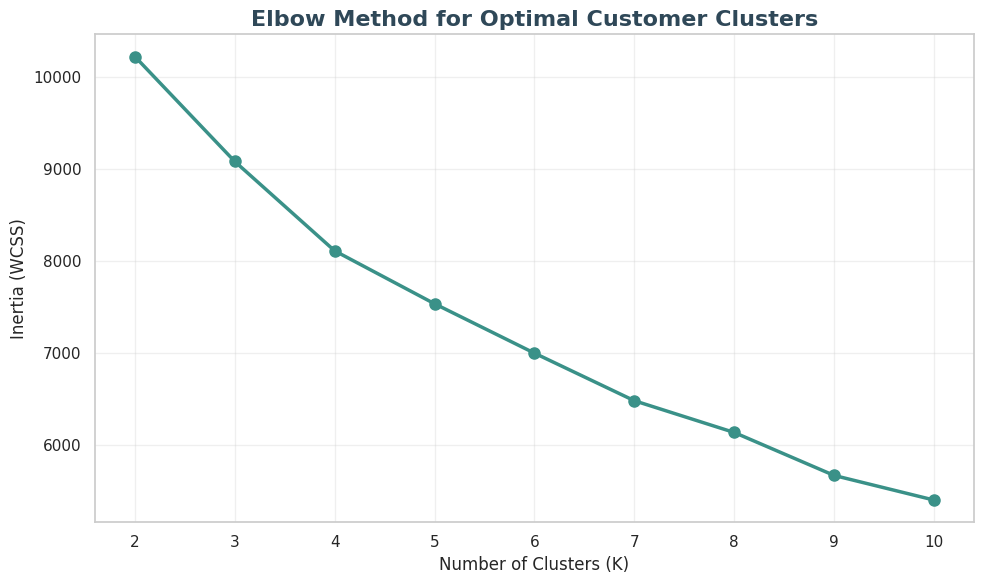

Inertia values for each K:
K = 2: 10224.79
K = 3: 9082.75
K = 4: 8110.13
K = 5: 7534.08
K = 6: 6996.61
K = 7: 6478.80
K = 8: 6133.19
K = 9: 5665.54
K = 10: 5397.61

Elbow Method chart saved successfully!


In [106]:
# TASK 7 — STEP 7.3: ELBOW METHOD

from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate inertia for different cluster counts
inertia_values = []
k_values = range(2, 11)

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    kmeans.fit(scaled_df)
    inertia_values.append(kmeans.inertia_)

# Plot Elbow Method
plt.figure(figsize=(10, 6))

plt.plot(
    k_values,
    inertia_values,
    marker="o",
    linewidth=2.5,
    markersize=8,
    color="#3A9188"
)

plt.title(
    "Elbow Method for Optimal Customer Clusters",
    fontsize=16,
    fontweight="bold",
    color="#2F4858"
)
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia (WCSS)")
plt.xticks(list(k_values))
plt.grid(alpha=0.3)

plt.tight_layout()

# Save chart
plt.savefig(
    CHART_DIR / "Task7_Chart1_Elbow_Method.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Inertia values for each K:")
for k, inertia in zip(k_values, inertia_values):
    print(f"K = {k}: {inertia:.2f}")

print("\nElbow Method chart saved successfully!")

### Observations

1. The inertia (WCSS) decreases as the number of clusters increases.
2. A larger number of clusters reduces within-cluster variation.
3. The curve shows a noticeable reduction in the rate of improvement around K = 4 to K = 5.
4. K = 4 and K = 5 are potential choices for customer segmentation.
5. The Silhouette Score will be used along with the Elbow Method to help select the final number of clusters.

## 7.4 Silhouette Score Analysis

Silhouette Scores for Different Cluster Numbers:


,Number_of_Clusters,Silhouette_Score
0,2,0.3202
1,3,0.2223
2,4,0.1986
3,5,0.1879
4,6,0.1977
5,7,0.2060
6,8,0.1849
7,9,0.1915
8,10,0.1918


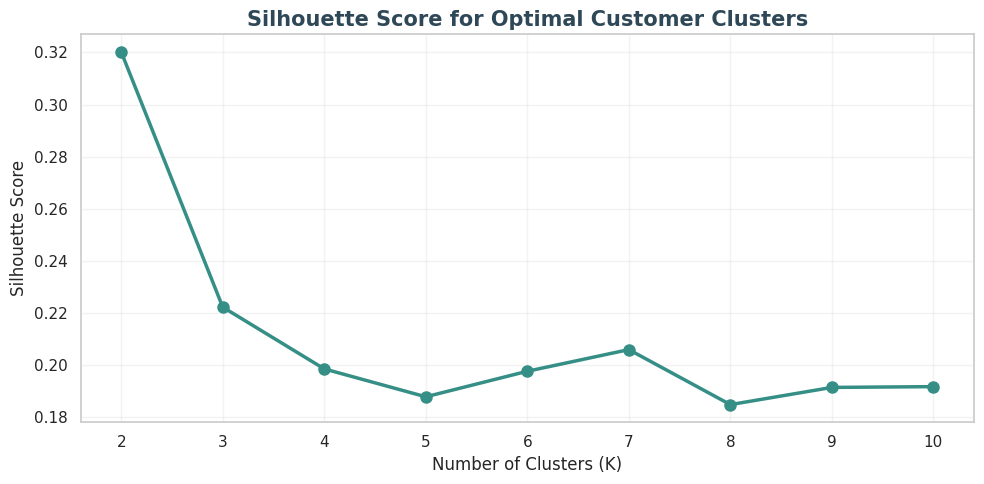

Silhouette analysis saved successfully!


In [107]:
# TASK 7 — STEP 7.4: SILHOUETTE SCORE ANALYSIS

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

silhouette_scores = {}

# Test different cluster numbers
for k in range(2, 11):

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    cluster_labels = kmeans.fit_predict(scaled_features)

    score = silhouette_score(
        scaled_features,
        cluster_labels
    )

    silhouette_scores[k] = score

# Display results
silhouette_df = pd.DataFrame(
    list(silhouette_scores.items()),
    columns=["Number_of_Clusters", "Silhouette_Score"]
)

silhouette_df = silhouette_df.round(4)

print("Silhouette Scores for Different Cluster Numbers:")
display(silhouette_df)

# Plot silhouette scores using the project colour theme
theme_colors = [
    "#2F4858", "#368F86", "#D9BD78",
    "#E39D70", "#D77965", "#8FAE88",
    "#527A91", "#C98F6D", "#7A8FA6"
]

plt.figure(figsize=(10, 5))

plt.plot(
    silhouette_df["Number_of_Clusters"],
    silhouette_df["Silhouette_Score"],
    marker="o",
    linewidth=2.5,
    markersize=8,
    color="#368F86"
)

plt.title(
    "Silhouette Score for Optimal Customer Clusters",
    fontsize=15,
    fontweight="bold",
    color="#2F4858"
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.xticks(range(2, 11))
plt.grid(alpha=0.25)

plt.tight_layout()

CHART_DIR = PROJECT_DIR / "04_Charts_and_Visuals"
CHART_DIR.mkdir(parents=True, exist_ok=True)

plt.savefig(
    CHART_DIR / "Task7_Chart2_Silhouette_Score.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Save results
silhouette_df.to_csv(
    REPORT_DIR / "Task7_Silhouette_Scores.csv",
    index=False
)

print("Silhouette analysis saved successfully!")

### Observations

1. The highest Silhouette Score is 0.3202 at K = 2.
2. The Silhouette Score decreases significantly when the number of clusters increases from 2 to 3.
3. For K values from 3 to 10, the scores remain comparatively low.
4. Based on the Silhouette Score, K = 2 provides the best separation among the tested cluster configurations.
5. Considering both the Elbow Method and Silhouette Score, K = 2 is selected for the initial K-Means customer segmentation.

## 7.5 Apply K-Means Clustering

In [108]:
# TASK 7 — STEP 7.5: APPLY K-MEANS CLUSTERING

from sklearn.cluster import KMeans

# Select the optimal number of clusters
optimal_k = 2

# Build and train the K-Means model
kmeans_model = KMeans(
    n_clusters=optimal_k,
    random_state=42,
    n_init=10
)

cluster_labels = kmeans_model.fit_predict(scaled_features)

# Add cluster labels to the segmentation dataset
segmentation_data["Cluster"] = cluster_labels

# Add cluster labels to the original EDA dataset
eda_df["Cluster"] = np.nan
eda_df.loc[segmentation_data.index, "Cluster"] = cluster_labels

# Display the number of customers in each cluster
cluster_counts = segmentation_data["Cluster"].value_counts().sort_index()

print("Customer Count in Each Cluster:")
display(cluster_counts.to_frame(name="Customer_Count"))

print("\nK-Means clustering completed successfully!")

Customer Count in Each Cluster:


,Customer_Count
Cluster,
0,957
1,1280



K-Means clustering completed successfully!


### Observations

1. K-Means successfully grouped 2,237 customers into two clusters.
2. Cluster 0 contains 957 customers, representing approximately 42.78% of the dataset.
3. Cluster 1 contains 1,280 customers, representing approximately 57.22% of the dataset.
4. Cluster 1 is larger than Cluster 0 by 323 customers.
5. Further analysis of income, spending, purchasing behaviour, age, and household characteristics is required to understand the differences between the two customer segments.

## 7.6 Customer Segment Profiling

In [109]:
# TASK 7 — STEP 7.6: CUSTOMER SEGMENT PROFILING

# Select important variables for understanding customer segments
profile_features = [
    "Age",
    "Income",
    "TotalSpending",
    "TotalPurchases",
    "TotalChildren",
    "NumWebVisitsMonth",
    "Recency",
    "TotalCampaignsAccepted"
]

# Calculate average values for each cluster
cluster_profile = eda_df.groupby("Cluster")[profile_features].mean().round(2)

print("Average Customer Profile for Each Cluster:")
display(cluster_profile)

# Calculate customer count and percentage
cluster_summary = eda_df.groupby("Cluster").agg(
    Customer_Count=("ID", "count"),
    Average_Spending=("TotalSpending", "mean"),
    Average_Income=("Income", "mean")
).round(2)

cluster_summary["Customer_Percentage"] = (
    cluster_summary["Customer_Count"] /
    cluster_summary["Customer_Count"].sum() * 100
).round(2)

print("\nCluster Summary:")
display(cluster_summary)

# Save the cluster profiles
cluster_profile.to_csv(
    REPORT_DIR / "Task7_Cluster_Profiles.csv"
)

cluster_summary.to_csv(
    REPORT_DIR / "Task7_Cluster_Summary.csv"
)

print("\nCustomer segment profiles saved successfully!")

Average Customer Profile for Each Cluster:


,Age,Income,TotalSpending,TotalPurchases,TotalChildren,NumWebVisitsMonth,Recency,TotalCampaignsAccepted
Cluster,,,,,,,,
0.0,57.34,71840.78,1185.36,19.33,0.52,3.67,49.48,0.76
1.0,53.42,37571.43,172.39,7.47,1.27,6.55,48.82,0.21



Cluster Summary:


,Customer_Count,Average_Spending,Average_Income,Customer_Percentage
Cluster,,,,
0.0,957,1185.36,71840.78,42.78
1.0,1280,172.39,37571.43,57.22



Customer segment profiles saved successfully!


### Observations

1. Cluster 0 contains 957 customers (42.78%) and has been identified as the High-Value Customer segment.
2. Cluster 1 contains 1,280 customers (57.22%) and has been identified as the Low-Value Customer segment.
3. Cluster 0 has a substantially higher average income of 71,840.78 compared with 37,571.43 in Cluster 1.
4. Average spending in Cluster 0 is 1,185.36, while Cluster 1 spends an average of 172.39.
5. Cluster 0 customers make an average of 19.33 purchases, compared with 7.47 purchases in Cluster 1.
6. Cluster 1 customers have more children on average (1.27) than Cluster 0 customers (0.52).
7. Cluster 1 has more monthly website visits (6.55) but fewer purchases, suggesting that higher website traffic does not necessarily result in higher purchasing activity.
8. Cluster 0 has a higher average campaign acceptance value (0.76) compared with Cluster 1 (0.21).
9. Income, spending, and purchase frequency are important characteristics distinguishing these two customer segments.

## 7.7 Customer Segment Visualization

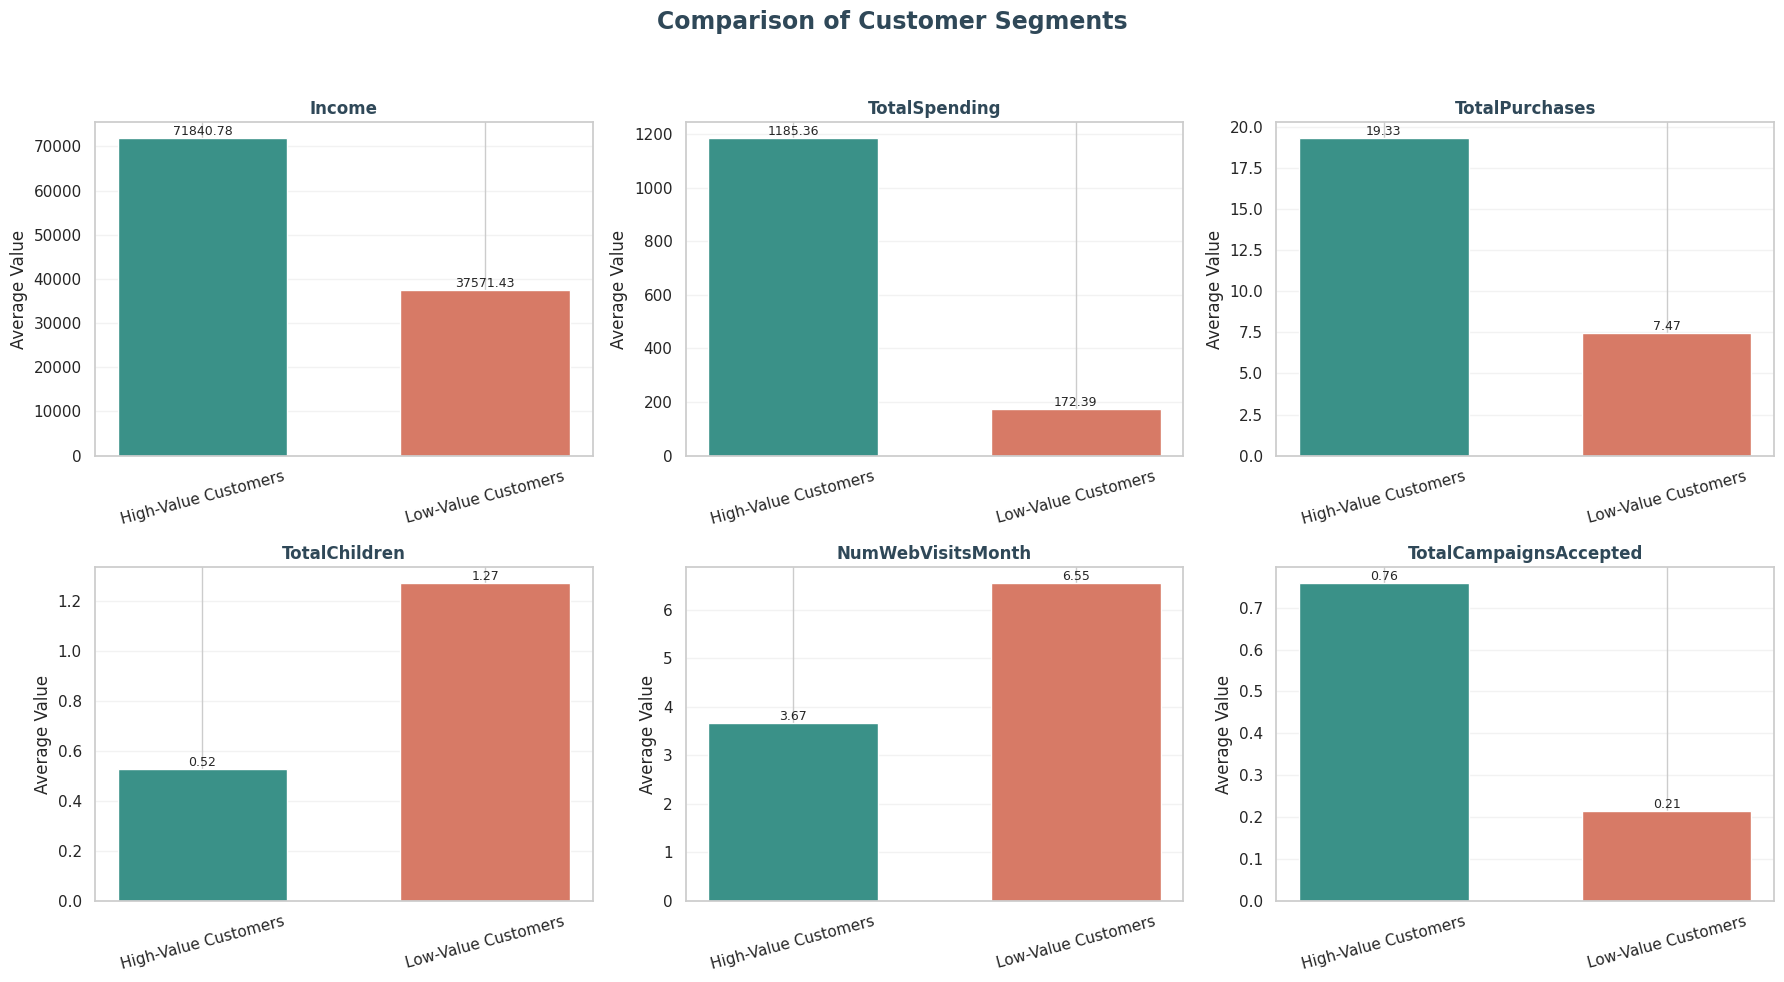

Customer segment comparison chart saved successfully!


In [110]:
# TASK 7 — STEP 7.7: CUSTOMER SEGMENT VISUALIZATION

# Select important variables for visualization
visual_features = [
    "Income",
    "TotalSpending",
    "TotalPurchases",
    "TotalChildren",
    "NumWebVisitsMonth",
    "TotalCampaignsAccepted"
]

# Calculate cluster averages
visual_profile = eda_df.groupby("Cluster")[visual_features].mean()

# Rename clusters for presentation
visual_profile.index = [
    "High-Value Customers",
    "Low-Value Customers"
]

# Create comparison charts
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

colors = ["#3A9188", "#D77A66"]

for ax, feature in zip(axes.flatten(), visual_features):

    values = visual_profile[feature]

    bars = ax.bar(
        values.index,
        values.values,
        color=colors,
        width=0.6
    )

    ax.set_title(
        feature.replace("_", " "),
        fontsize=12,
        fontweight="bold",
        color="#2F4858"
    )

    ax.set_ylabel("Average Value")
    ax.tick_params(axis="x", rotation=15)
    ax.grid(axis="y", alpha=0.25)

    for bar in bars:
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height(),
            f"{bar.get_height():.2f}",
            ha="center",
            va="bottom",
            fontsize=9
        )

plt.suptitle(
    "Comparison of Customer Segments",
    fontsize=17,
    fontweight="bold",
    color="#2F4858"
)

plt.tight_layout(rect=[0, 0, 1, 0.95])

plt.savefig(
    CHART_DIR / "Task7_Chart3_Customer_Segment_Comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Customer segment comparison chart saved successfully!")

### Observations

1. The comparison chart highlights clear differences between the two customer segments.
2. High-Value Customers have higher average income, total spending, and purchase frequency.
3. Low-Value Customers have more children on average and visit the website more frequently.
4. Despite having more website visits, Low-Value Customers make fewer purchases.
5. High-Value Customers show greater campaign acceptance than Low-Value Customers.
6. These differences indicate that income, spending, purchase frequency, and campaign acceptance are useful characteristics for understanding customer segments.

### Task 7: Customer Segmentation — Conclusion

K-Means clustering was applied to segment customers based on income, spending, purchase frequency, household characteristics, age, recency, and website visits.

The Elbow Method and Silhouette Score were used to evaluate the number of clusters. Based on the highest Silhouette Score of 0.3202, two clusters were selected.

The analysis identified two customer segments:

- **High-Value Customers (Cluster 0):** 957 customers (42.78%) with higher income, spending, purchase frequency, and campaign acceptance.
- **Low-Value Customers (Cluster 1):** 1,280 customers (57.22%) with lower average income and spending, fewer purchases, and more website visits.

The segmentation provides useful insights for developing targeted marketing strategies, improving customer engagement, and increasing sales.

The results should be interpreted as exploratory customer groups because clustering quality is moderate and may be affected by extreme income values.

# TASK 8: BUSINESS RECOMMENDATIONS

## 8.1 Key Findings from Customer Analysis

1. Product Preferences:
   Wines contribute 50.17% of total product spending, followed by meat products at 27.56%.

2. Customer Income:
   Customers in higher income groups have considerably higher average spending than customers in lower income groups.

3. Household Characteristics:
   Customers without children have the highest average spending compared with customers having children.

4. Customer Segmentation:
   High-Value Customers represent 42.78% of customers and have an average spending of 1,185.36.

5. Campaign Performance:
   The most recent campaign (Response) has the highest acceptance rate at 14.91%.

6. Campaign Engagement:
   Customers who accepted at least one campaign have average spending of 1,001.33, compared with 458.11 among customers who accepted none.

7. Shopping Channels:
   Physical stores account for 46.18% of purchases, followed by web purchases at 32.58% and catalog purchases at 21.23%.

8. Website Engagement:
   Website visits have a very weak negative correlation with web purchases (-0.056), indicating that more visits do not necessarily lead to more purchases.

## 8.2 Business Recommendations

In [111]:
# TASK 8 — STEP 8.2: SAVE BUSINESS RECOMMENDATIONS

recommendations = [
    {
        "No": 1,
        "Finding": "Wines contribute 50.17% of total spending.",
        "Recommendation": "Develop wine-focused promotions and product bundles.",
        "Expected_Benefit": "Increase sales in the strongest product category."
    },
    {
        "No": 2,
        "Finding": "Wine and meat together contribute 77.73% of spending.",
        "Recommendation": "Introduce complementary wine-and-meat bundles.",
        "Expected_Benefit": "Encourage cross-category purchases."
    },
    {
        "No": 3,
        "Finding": "High-value customers spend an average of 1185.36.",
        "Recommendation": "Introduce loyalty rewards and exclusive offers.",
        "Expected_Benefit": "Improve customer retention and repeat purchases."
    },
    {
        "No": 4,
        "Finding": "Low-value customers spend an average of 172.39.",
        "Recommendation": "Offer targeted introductory deals and personalized recommendations.",
        "Expected_Benefit": "Encourage purchase frequency and spending growth."
    },
    {
        "No": 5,
        "Finding": "The latest campaign has a 14.91% acceptance rate.",
        "Recommendation": "Study successful campaign characteristics and test similar approaches.",
        "Expected_Benefit": "Improve future campaign effectiveness."
    },
    {
        "No": 6,
        "Finding": "Physical stores account for 46.18% of purchases.",
        "Recommendation": "Strengthen in-store promotions while improving online convenience.",
        "Expected_Benefit": "Maintain the strongest channel and support digital growth."
    },
    {
        "No": 7,
        "Finding": "Website visits have a very weak negative correlation with web purchases.",
        "Recommendation": "Improve website navigation, product discovery, and checkout experience.",
        "Expected_Benefit": "Reduce friction between browsing and purchasing."
    },
    {
        "No": 8,
        "Finding": "Higher-income customers have higher average spending.",
        "Recommendation": "Test premium product recommendations and personalized offers.",
        "Expected_Benefit": "Increase average order value."
    }
]

recommendations_df = pd.DataFrame(recommendations)

recommendations_df.to_csv(
    REPORT_DIR / "Task8_Business_Recommendations.csv",
    index=False
)

print("Business recommendations saved successfully!")
display(recommendations_df)

Business recommendations saved successfully!


,No,Finding,Recommendation,Expected_Benefit
0,1,Wines contribute 50.17% of total spending.,Develop wine-focused promotions and product bu...,Increase sales in the strongest product category.
1,2,Wine and meat together contribute 77.73% of sp...,Introduce complementary wine-and-meat bundles.,Encourage cross-category purchases.
2,3,High-value customers spend an average of 1185.36.,Introduce loyalty rewards and exclusive offers.,Improve customer retention and repeat purchases.
3,4,Low-value customers spend an average of 172.39.,Offer targeted introductory deals and personal...,Encourage purchase frequency and spending growth.
4,5,The latest campaign has a 14.91% acceptance rate.,Study successful campaign characteristics and ...,Improve future campaign effectiveness.
5,6,Physical stores account for 46.18% of purchases.,Strengthen in-store promotions while improving...,Maintain the strongest channel and support dig...
6,7,Website visits have a very weak negative corre...,"Improve website navigation, product discovery,...",Reduce friction between browsing and purchasing.
7,8,Higher-income customers have higher average sp...,Test premium product recommendations and perso...,Increase average order value.


# TASK 8: BUSINESS RECOMMENDATIONS — CONCLUSION

The customer analysis identified important patterns in product preferences, customer spending, campaign responses, shopping channels, and customer segmentation.

The findings show that wines and meat products contribute a major share of total spending. Higher-income customers and customers without children demonstrate higher average spending. The campaign analysis identified differences in acceptance rates, while shopping channel analysis showed that physical stores account for the largest share of purchases.

K-Means clustering identified two customer segments: High-Value Customers (42.78%) and Low-Value Customers (57.22%). These segments differ in income, spending, purchase frequency, website visits, and campaign acceptance.

Based on these findings, eight business recommendations were proposed, focusing on product promotions, customer loyalty, personalized marketing, campaign improvement, and shopping channel optimization.

These recommendations can help the business develop more targeted marketing strategies, improve customer engagement, and identify opportunities for sales growth. Their actual impact should be evaluated through future campaigns and controlled experiments.

**Overall, this project demonstrates how customer data analysis can support better business decisions and more effective customer relationship management.**